# Desiertos de recarga bip! en Santiago · Notebook integral

**IIC2433 · Minería de Datos · Entrega final 2026-2**

¿En qué Zonas 777 coinciden muchos inicios de viaje y una baja accesibilidad a recarga bip!, y qué paraderos conviene evaluar para ampliar la cobertura?

El diagnóstico usa los polígonos disponibles de la zonificación denominada **Zona 777**. La matriz de cuatro cuadrantes conserva el criterio de priorización del avance y el ranking por paradero señala emplazamientos concretos. Se agrega una simulación de cobertura para comparar dos maneras de distribuir un mismo número de nuevos puntos.

| Pregunta | Método y salida | Evaluación |
|---|---|---|
| ¿Dónde falta acceso? | Distancia UTM con `cKDTree`, cruce punto-polígono y cuatro cuadrantes | Cobertura a 300 y 500 m y sensibilidad al radio |
| ¿Qué perfiles tienen las zonas? | PCA y K-Means, que entrega etiquetas de perfil | Varianza explicada, cargas, curva del codo y silueta |
| ¿Cuántas subidas laborales registra un paradero? | Ridge y Random Forest **regresor**, que estiman subidas/día | MAE, RMSE y R² sobre comunas retenidas. Baseline de la media |
| ¿Cuántos viajes registrados empiezan por hora? | ARIMA y SARIMA, que pronostican una serie agregada | MAE y RMSE cronológicos. Baseline de la misma hora del día anterior |
| ¿Dónde conviene evaluar nuevos puntos? | Ranking observado y selección por cobertura marginal | Subidas preexistentes al alcance de los sitios simulados, con idéntico presupuesto |

**Respuesta al profesor.** Ridge es regresión lineal regularizada. Junto con Random Forest estima una variable continua usando características de cada paradero, en comunas retenidas. Su utilidad es contrastar la capacidad predictiva y el aporte de las variables de recarga. La ubicación de candidatos se deriva de demanda observada, distancias y cobertura marginal. SARIMA responde a la planificación horaria agregada. PCA y K-Means describen perfiles sin una etiqueta de referencia. Cada comparación usa el mismo objetivo, conjunto de prueba y unidad dentro de su pregunta.

### Recorrido del notebook

1. Inventario, diccionario de campos y enlace territorial.
2. EDA del catastro, subidas oficiales, viajes y comunas.
3. Accesibilidad peatonal aproximada, cuadrantes y sensibilidad.
4. PCA, K-Means y diagnóstico de perfiles.
5. Regresión con validación geográfica y pronóstico con validación temporal.
6. Balance observacional, ranking, simulación, mapa e integridad.

### Reproducción

Instale `requirements.txt`, abra este notebook con el kernel de ese entorno y ejecute todas las celdas desde la carpeta del proyecto. Se leen los originales y se exportan las tablas, las figuras principales y `Live_Demo_BIP.html` a `resultados_integral/`. Todas las funciones de `proyecto_bip.py` y la plantilla HTML están incluidas en las celdas. Los notebooks históricos sirven como referencia metodológica y no son insumos de ejecución. La lectura de los siete CSV se hace por bloques y recorre varios GB. El HTML muestra los polígonos y los resultados sin conexión.

### Fuentes y alcance

- ADATRAP, **11–17 de abril de 2026**. Cada fila con fecha válida cuenta como un viaje registrado, sin expansión. Se leen la fecha y la zona de origen, más etapas y distancia euclidiana para la EDA. El diagnóstico zonal usa lunes a viernes y el pronóstico usa la semana completa. [Matrices de Viaje DTPM](https://www.dtpm.cl/index.php/documentos/matrices-de-viaje)
- DTPM, `Subidas_Paradero_Estacion_2026.04_v3.xlsx`. Subidas promedio por día laboral del **13–17 de abril**. Se filtra `Modo=BUS` y se suma por código interno. Las subidas incluyen etapas y transbordos. [Subidas por paradero y diccionarios](https://www.dtpm.cl/index.php/documentos/matrices-de-viaje)
- DTPM, **GTFS del 18 de abril de 2026**, incorporado como fuente complementaria. El identificador `stop_id` coincide con el código público de DTPM. El GTFS entra en vigencia un día después del último dato de demanda. Se usa como aproximación a la ubicación y oferta del período. [Archivo oficial GTFS](https://www.dtpm.cl/descargas/gtfs/GTFS_20260418.zip)
- Subsecretaría de Transportes, **catastro local del 17 de septiembre de 2024** según nombres y metadatos de los cinco XLSX utilizados. El Portal de Datos Abiertos muestra fechas de actualización de ficha del 22 de julio de 2026. Para fechar la cobertura del análisis usamos la copia local y la vigencia operativa de esos puntos en abril queda por verificar. Para Metro usamos ubicaciones GTFS conciliadas con el catastro. Se deduplican las coordenadas UTM 19S exactas. [Catastros bip! del Portal de Datos Abiertos](https://datos.gob.cl/organization/subsecretaria_de_transporte)
- `Zonas777_V07_04_2014.shp` y sus archivos asociados. El universo usa los códigos que trae la cartografía, incluido el 0, que tiene polígono identificado. La unión conserva todos sus códigos distintos. Se supone WGS84 en el archivo sin `.prj` y se contrasta contra la zona del diccionario de paraderos.

In [1]:
from pathlib import Path
import re, unicodedata, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from scipy.spatial import cKDTree
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.neighbors import NearestNeighbors
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from pyproj import Transformer

from threadpoolctl import threadpool_limits
from IPython.display import Markdown
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon, Patch
from scipy.spatial.distance import pdist
from sklearn.base import clone
from collections import Counter
from zipfile import ZipFile
from html import escape
import openpyxl
import shapely
from sklearn.compose import TransformedTargetRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import silhouette_samples

SEMILLA = 42
RADIO_CERCANO_M, RADIO_AISLAMIENTO_M = 300, 500
TOP_N, SEPARACION_CANDIDATOS_M = 20, 200
RAIZ = Path.cwd().resolve()
ORIG, RESULTADOS = RAIZ / 'datos_originales', RAIZ / 'resultados_integral'
if not ORIG.is_dir():
    raise FileNotFoundError('Ejecute desde la carpeta que contiene datos_originales y el notebook.')
RESULTADOS.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def guardar_figura(fig, nombre):
    fig.tight_layout()
    fig.savefig(RESULTADOS / nombre, dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()

def numero(valor, decimales=0):
    return f'{valor:,.{decimales}f}'.translate(str.maketrans({',':'.', '.':','}))

## Vinculación con el material de IIC2433

| Método del proyecto | Material revisado | Uso y procedencia |
|---|---|---|
| Estandarización y PCA | [Clase 1, p. 23](02_Clases/Clase%201%20DM.pdf#page=23), [Clase 2, pp. 20–26](02_Clases/Clase%202%20DM.pdf#page=20) y [Actividad 1 de PCA](03_Actividades/Act1_Reducción_Dimensionalidades_PCA.ipynb) | Se aplican a cinco atributos zonales. Se **reutilizan y adaptan** las líneas de varianza individual y acumulada de la actividad para el scree plot. |
| K-Means, codo y silueta | [Clase 4, pp. 7–12](02_Clases/Clase%204%20DM.pdf#page=7) | Se ajusta K-Means en los cinco atributos estandarizados. El codo se muestra como diagnóstico y se elige k por silueta. La implementación es del proyecto. |
| Evaluación cronológica | [Clase 6, pp. 5–7](02_Clases/Clase%206%20DM.pdf#page=5) y [Series de Tiempo 1](03_Actividades/Series_de_Tiempo_1.ipynb) | Referencia para respetar el orden temporal. El proyecto usa tres cortes de entrenamiento creciente y una referencia ingenua de 24 h. |
| ARIMA y SARIMA | [Clase 7, pp. 7–17](02_Clases/Clase%207%20DM%20(2026-2).pdf#page=7) y [Actividad de ARIMA](03_Actividades/Actividad_Series_de_Tiempo_ARIMA.ipynb) | Se **reutiliza y adapta** el bloque de pronóstico SARIMA con `get_forecast`, `predicted_mean` y `conf_int`. La actividad trabaja con frecuencia mensual y período 12. El proyecto usa frecuencia horaria y período 24. Los órdenes son los del experimento del proyecto y tres días de prueba permiten una evaluación exploratoria. |

Las clases 3, 5, 8, 9 y 10 cubren t-SNE/UMAP, GMM, reglas de asociación, redes bayesianas y texto, respectivamente. Esos métodos y sus actividades quedan como material de consulta. Tampoco se usaron ADF, ACF/PACF, Prophet ni búsqueda automática de órdenes en el pronóstico presentado. El análisis por propensión es una comparación observacional del proyecto y corresponde a una metodología distinta de las redes bayesianas. Los cruces espaciales con GTFS, cKDTree, la regresión por comuna retenida y la simulación de cobertura son componentes propios del proyecto.

Los fragmentos adaptados están incorporados en las celdas y usan las fuentes de Santiago. Los archivos del curso funcionan como referencias de lectura.

## 1. Inventario de fuentes y cruce territorial

| Fuente | Campos usados | Control aplicado |
|---|---|---|
| Libros de recarga bip! | `ESTE`, `NORTE`, `ENTIDAD`, `COMUNA` | La fila de encabezado se detecta por nombre. Se validan coordenadas y se elimina duplicación exacta de ubicaciones. |
| Libro DTPM | `Tipo_dia`, `Modo`, `Paradero`, `Paradero Usuario`, `Comuna`, `Media_hora`, `Subidas_Promedio` | Los tabulados oficiales sirven para el contexto multimodal. La tabla de modelado suma solo las filas BUS laborales por código interno. |
| ZIP GTFS | `stop_id`, `stop_lat`, `stop_lon`, `route_type`, `route_id`, `trip_id` | El código público enlaza subidas con la ubicación y permite contar rutas distintas de bus; este conteo no equivale a frecuencia. |
| `DIC_777.xlsx` y capa Zona 777 | `DISENO_777`, `X`, `Y`, `ZONA777` | El diccionario histórico permite medir concordancia de la asignación espacial. El código oficial identifica cada polígono; se unen sus piezas si aparecen en varias filas. |
| CSV de viajes ADATRAP | `tiempo_inicio_viaje`, `zona_inicio_viaje`, `n_etapas`, `distancia_eucl` | La hora debe pertenecer al día del archivo. Las etapas y distancias se analizan con sus respectivos denominadores válidos. |

**Normalización y lectura.** `normalizar` armoniza tildes y mayúsculas para unir etiquetas. `float_col` convierte columnas numéricas en los Excel históricos. `leer_bip` identifica libros y hojas con coordenadas. `leer_paraderos` valida el esquema, limpia coordenadas UTM y conserva el diccionario como referencia histórica.
### Recarga en estaciones de Metro

El DTPM y Red Movilidad confirman recarga física bip! en las estaciones de Metro. El XLSX de septiembre de 2024 ya entraba en el árbol de distancias, pero sus coordenadas no siempre representaban la ubicación correcta. Sus 143 filas por línea y estación se concilian por nombre con 126 estaciones del GTFS de abril de 2026. Se retiran las coordenadas antiguas de Metro y se usa una ubicación representativa de estación por cada nombre conciliado. El XLSX respalda el servicio y el GTFS aporta la ubicación. Los registros de otros proveedores conservan sus coordenadas. `auditoria_recarga_metro.csv` registra la correspondencia y el desfase de cada fila. La ubicación representativa aproxima el acceso al recinto: el cálculo usa distancia en línea recta y los accesos y horarios concretos se verifican en terreno.

[Política de recarga de Red Movilidad](https://www.red.cl/tarifas-y-recargas/tarjeta-bip/) · [Informe de Gestión 2025 DTPM, p. 95](https://www.dtpm.cl/descargas/memoria/Informe%20de%20Gestion%20DTPM2025.pdf#page=95) · [Ficha del XLSX de estaciones Metro](https://datos.gob.cl/dataset/33355/resource/3d54e961-d81b-4507-aeee-7a433e00a9bf)

Se incorpora además un emplazamiento en la **Intermodal Aeropuerto**, porque Red documenta dos máquinas de venta y recarga en el recinto desde septiembre de 2025. La coordenada del paradero público `PJ2005` representa la intermodal en el cálculo, por lo que ambos registros quedan en la misma ubicación del modelo. La distancia al equipo dentro del recinto requiere medición directa. [Anuncio oficial de Red Movilidad](https://www.red.cl/red-comunica/buses-red-al-aeropuerto-reportan-mas-de-2-millones-y-medio-de-transacciones-y-suman-maquinas-de-venta-de-tarjetas-bip/)

In [2]:
def normalizar(valor):
    if pd.isna(valor):
        return ""
    texto = unicodedata.normalize("NFKD", str(valor))
    return "".join(c for c in texto if not unicodedata.combining(c)).strip().upper()

def float_col(serie):
    texto = serie.astype('string').str.strip().str.replace(' ', '', regex=False)
    texto = texto.str.replace(',', '.', regex=False)
    return pd.to_numeric(texto, errors='coerce').astype('float64')

def archivos_excel(carpeta):
    if not carpeta.is_dir():
        raise FileNotFoundError(f'Falta la carpeta requerida: {carpeta}')
    return sorted(p for p in carpeta.rglob('*.xlsx') if not p.name.startswith('~$'))

def leer_bip(carpeta):
    partes, bitacora = [], []
    libros = archivos_excel(carpeta)
    if not libros:
        raise FileNotFoundError(f'No existen .xlsx en {carpeta}')
    for ruta in libros:
        with pd.ExcelFile(ruta) as libro:
            for hoja in libro.sheet_names:
                muestra = pd.read_excel(libro, sheet_name=hoja, header=None, nrows=30)
                fila_cabecera = None
                for idx, fila in muestra.iterrows():
                    etiquetas = {normalizar(v) for v in fila.values}
                    if 'ESTE' in etiquetas and 'NORTE' in etiquetas:
                        fila_cabecera = int(idx)
                        break
                if fila_cabecera is None:
                    bitacora.append(f'Omitida {ruta.name} / {hoja}: sin columnas ESTE y NORTE')
                    continue
                tabla = pd.read_excel(libro, sheet_name=hoja, header=fila_cabecera)
                tabla.columns = [normalizar(c) for c in tabla.columns]
                tabla = tabla.loc[:, ~tabla.columns.duplicated()]
                for columna in ('CODIGO', 'ENTIDAD', 'COMUNA', 'DIRECCION', 'NOMBRE FANTASIA'):
                    if columna not in tabla.columns:
                        tabla[columna] = ''
                tabla['ESTE'] = float_col(tabla['ESTE'])
                tabla['NORTE'] = float_col(tabla['NORTE'])
                tabla['ORIGEN_ARCHIVO'] = ruta.name
                partes.append(tabla[['CODIGO','ENTIDAD','COMUNA','DIRECCION','ESTE','NORTE','ORIGEN_ARCHIVO','NOMBRE FANTASIA']])
    if not partes:
        raise ValueError('Ninguna hoja de recarga tiene encabezados válidos ESTE/NORTE.')
    tabla = pd.concat(partes, ignore_index=True)
    n_inicial = len(tabla)
    # Región metropolitana: rangos conservadores solo para evitar coordenadas erróneas.
    tabla = tabla[tabla.ESTE.between(250000, 400000) & tabla.NORTE.between(6200000, 6400000)].copy()
    tabla['COMUNA_NORM'] = tabla.COMUNA.map(normalizar)
    tabla['ENTIDAD'] = tabla.ENTIDAD.map(normalizar)
    # Las filas Metro por línea se conservan para la auditoría antes de deduplicar ubicaciones.
    tabla = tabla.rename(columns={'NOMBRE FANTASIA':'NOMBRE_FANTASIA'})
    print(f'BIP: {n_inicial:,} registros brutos → {len(tabla):,} filas con coordenadas válidas.')
    for advertencia in bitacora[:8]: print('AVISO:', advertencia)
    return tabla

def leer_paraderos(ruta):
    if not ruta.is_file():
        raise FileNotFoundError(f'Falta diccionario geográfico: {ruta}')
    tabla = pd.read_excel(ruta, sheet_name='DIC_777')
    columnas = ['PARADA','SUBIDAS_LABORAL','BAJADAS_LABORAL','COMUNA','REFERENCIA','DISENO_777','X_UTM','Y_UTM']
    # Se valida el esquema del diccionario incluido antes de renombrar.
    nombres = [normalizar(c) for c in tabla.columns]
    if set(columnas).issubset(nombres):
        tabla.columns = nombres
        tabla = tabla[columnas].copy()
    elif nombres == ['PARADA/EST.METRO','SUBIDAS DIA LABORAL POR PARADA',
                     'BAJADAS DIA LABORAL POR PARADA','COMUNA','REFERENCIA','DISENO_777','X','Y']:
        tabla.columns = columnas
    else:
        raise ValueError(f'DIC_777: esquema inesperado ({list(tabla.columns)}). Revisar diccionario.')
    for c in ['SUBIDAS_LABORAL','BAJADAS_LABORAL','X_UTM','Y_UTM']:
        tabla[c] = float_col(tabla[c])
    tabla['PARADA'] = tabla.PARADA.astype('string').str.strip().str.upper()
    tabla['COMUNA'] = tabla.COMUNA.map(normalizar)
    tabla['REFERENCIA'] = tabla.REFERENCIA.fillna('').astype(str)
    n_inicial = len(tabla)
    tabla = tabla[tabla.X_UTM.between(250000,400000) & tabla.Y_UTM.between(6200000,6400000)]
    tabla = tabla.dropna(subset=['PARADA'])
    tabla = tabla[tabla.PARADA.str.len().gt(0)]
    tabla = tabla.drop_duplicates(subset=['PARADA','X_UTM','Y_UTM']).reset_index(drop=True)
    print(f'PARADEROS: {n_inicial:,} registros brutos → {len(tabla):,} paradas/ubicaciones válidas.')
    return tabla

**Demanda por paradero y oferta del GTFS.** `leer_demanda_bus` recorre la hoja grande en modo de solo lectura, agrega subidas por parada y calcula la parte de punta. `leer_paraderos_gtfs` comprueba la versión del ZIP, filtra rutas de bus y enlaza las tablas con las claves del estándar. Devuelve una fila por `stop_id` con coordenadas proyectadas y número de rutas distintas.

In [3]:
def leer_demanda_bus(ruta):
    """DTPM informa subidas promedio por media hora, tipo de día y modo."""
    libro = openpyxl.load_workbook(ruta, read_only=True, data_only=True)
    try:
        filas = libro["SUBIDAS_2026_04"].values
        columnas = tuple(next(filas))
        esperadas = ("Tipo_dia", "Modo", "Paradero", "Paradero Usuario", "Comuna",
                     "Media_hora", "Subidas_Promedio")
        if columnas != esperadas:
            raise ValueError(f"Esquema de subidas DTPM inesperado: {columnas}")
        registros = [(str(codigo).strip().upper(), str(publico or "").strip().upper(),
                      str(comuna or ""), media.hour, float(subidas))
                     for dia, modo, codigo, publico, comuna, media, subidas in filas
                     if dia == "LABORAL" and modo == "BUS" and codigo and media is not None
                     and subidas is not None and float(subidas) >= 0]
    finally:
        libro.close()
    datos = pd.DataFrame(registros, columns=["PARADA", "CODIGO_PUBLICO", "COMUNA_DTPM",
                                            "HORA", "SUBIDAS_LABORAL"])
    datos["subidas_punta"] = datos.SUBIDAS_LABORAL.where(
        datos.HORA.between(7, 8) | datos.HORA.between(17, 19), 0)
    return datos.groupby("PARADA", as_index=False).agg(
        CODIGO_PUBLICO=("CODIGO_PUBLICO", "first"), COMUNA_DTPM=("COMUNA_DTPM", "first"),
        SUBIDAS_LABORAL=("SUBIDAS_LABORAL", "sum"), subidas_punta=("subidas_punta", "sum"))


def leer_paraderos_gtfs(ruta):
    """stop_id contiene los códigos públicos de la red. Conserva solo rutas de bus."""
    from pyproj import Transformer

    with ZipFile(ruta) as gtfs:
        def tabla(nombre, columnas):
            with gtfs.open(nombre + ".txt") as archivo:
                return pd.read_csv(archivo, usecols=columnas, dtype="str")

        version = tabla("feed_info", ["feed_start_date", "feed_version"])
        if version.feed_start_date.tolist() != ["20260418"]:
            raise ValueError("Se espera el GTFS de DTPM del 18 de abril de 2026")
        paradas = tabla("stops", ["stop_id", "stop_name", "stop_lat", "stop_lon"])
        rutas = tabla("routes", ["route_id", "route_type"])
        buses = rutas.loc[rutas.route_type.eq("3"), "route_id"]
        viajes = tabla("trips", ["trip_id", "route_id"])
        viajes_bus = viajes.loc[viajes.route_id.isin(buses)]
        horarios = tabla("stop_times", ["trip_id", "stop_id"])
        rutas_por_parada = (horarios.merge(viajes_bus, on="trip_id", validate="m:1")
                            .groupby("stop_id").route_id.nunique().rename("rutas_bus_gtfs"))
    paradas = paradas.join(rutas_por_parada, on="stop_id", how="inner")
    lat = pd.to_numeric(paradas.stop_lat, errors="coerce")
    lon = pd.to_numeric(paradas.stop_lon, errors="coerce")
    paradas = paradas.loc[lat.between(-35, -32) & lon.between(-72, -69)].copy()
    convertir = Transformer.from_crs(4326, 32719, always_xy=True)
    paradas["X_UTM"], paradas["Y_UTM"] = convertir.transform(
        lon.loc[paradas.index].to_numpy(), lat.loc[paradas.index].to_numpy())
    paradas = paradas.rename(columns={"stop_id": "CODIGO_PUBLICO", "stop_name": "REFERENCIA"})
    paradas["REFERENCIA"] = paradas.REFERENCIA.str.replace(r"^[A-Z0-9]+-", "", regex=True)
    return paradas[["CODIGO_PUBLICO", "REFERENCIA", "X_UTM", "Y_UTM", "rutas_bus_gtfs"]]

**Zonificación.** `leer_poligonos` repara geometrías y las proyecta a UTM 19S. Ante la ausencia de `.prj`, se contrasta la asignación con `DIC_777`. `asignar_poligonos` usa un índice espacial STRtree y la relación `covered_by`, que incluye el borde. Si hay más de una coincidencia, elige la zona de menor área y desempata por código. Los puntos fuera de la capa quedan sin zona.

In [4]:
def leer_poligonos(ruta):
    import shapefile
    import shapely
    from pyproj import Transformer

    # El archivo no trae .prj. Sus coordenadas corresponden a longitudes y latitudes de Santiago.
    proyectar = Transformer.from_crs(4326, 32719, always_xy=True).transform
    componentes, comunas = {}, {}
    with shapefile.Reader(str(ruta), encoding="latin1") as lector:
        if not (-72 < lector.bbox[0] < lector.bbox[2] < -69 and
                -35 < lector.bbox[1] < lector.bbox[3] < -32):
            raise ValueError("La extensión del shapefile no es compatible con Santiago en grados")
        for registro in lector.iterShapeRecords():
            zona = int(registro.record["ZONA777"])
            forma = shapely.make_valid(shapely.geometry.shape(registro.shape.__geo_interface__))
            poligonos = [p for p in shapely.get_parts(forma) if p.geom_type in {"Polygon", "MultiPolygon"}]
            if poligonos:
                componentes.setdefault(zona, []).extend(shapely.transform(p, proyectar, interleaved=False) for p in poligonos)
                comunas[zona] = registro.record["COMUNA"].strip().title()
    geometrias = {zona: shapely.union_all(componentes[zona]) for zona in sorted(componentes)}
    return geometrias, comunas


def asignar_poligonos(geometrias, x, y):
    import shapely

    codigos = np.array(list(geometrias))
    formas = list(geometrias.values())
    arbol = shapely.STRtree(formas)
    puntos, figuras = arbol.query(shapely.points(x, y), predicate="covered_by")
    coincidencias = pd.DataFrame({"fila": puntos, "zona": codigos[figuras],
                                  "area": shapely.area(formas)[figuras]})
    # En bordes o solapamientos, el polígono menor tiene precedencia. Luego, el código menor.
    asignadas = (coincidencias.sort_values(["area", "zona"]).drop_duplicates("fila")
                 .set_index("fila").zona.reindex(range(len(x))).astype("Int64"))
    return asignadas, int(coincidencias.fila.duplicated().sum())

In [5]:
def leer_estaciones_gtfs(ruta):
    """Ubica estaciones de Metro y EFE a partir de las rutas del GTFS utilizado."""
    from pyproj import Transformer

    modos = {"M": "Metro", "MT": "Tren"}
    with ZipFile(ruta) as gtfs:
        rutas = pd.read_csv(gtfs.open("routes.txt"), usecols=["route_id", "agency_id"], dtype=str)
        rutas["modo"] = rutas.agency_id.map(modos)
        viajes = pd.read_csv(gtfs.open("trips.txt"), usecols=["trip_id", "route_id"], dtype=str)
        viajes = viajes.merge(rutas.dropna(subset="modo")[["route_id", "modo"]], on="route_id", validate="m:1")
        paradas = pd.read_csv(gtfs.open("stop_times.txt"), usecols=["trip_id", "stop_id"], dtype=str)
        paradas = paradas.merge(viajes[["trip_id", "modo"]], on="trip_id", validate="m:1")
        paradas = paradas[["stop_id", "modo"]].drop_duplicates()
        ubicaciones = pd.read_csv(gtfs.open("stops.txt"), usecols=[
            "stop_id", "stop_name", "parent_station", "stop_lon", "stop_lat"]).set_index("stop_id")
    padres = paradas.stop_id.map(ubicaciones.parent_station)
    estaciones = (paradas.assign(stop_id=padres.where(padres.isin(ubicaciones.index), paradas.stop_id))
                  .drop_duplicates().join(ubicaciones, on="stop_id"))
    estaciones["nombre"] = estaciones.stop_name.str.replace(r"\s*\(And[eé]n\s*\d+\)\s*$", "", case=False, regex=True)
    estaciones = estaciones.dropna(subset=["nombre", "stop_lon", "stop_lat"])
    # EFE también publica andenes separados sin parent_station; se agrupan por nombre de estación.
    estaciones = estaciones.groupby(["modo", "nombre"], as_index=False)[["stop_lon", "stop_lat"]].mean()
    transformar = Transformer.from_crs(4326, 32719, always_xy=True)
    estaciones["x"], estaciones["y"] = transformar.transform(
        estaciones.stop_lon.to_numpy(), estaciones.stop_lat.to_numpy())
    return estaciones[["modo", "nombre", "x", "y"]]


def conciliar_recarga_metro(catastro, estaciones, origen_gtfs):
    """Conserva la evidencia de recarga del XLSX y ubica cada estación con el GTFS."""
    def clave_estacion(nombre):
        nombre = re.sub(r"\s+L[1-6]A?$", "", normalizar(nombre))
        clave = re.sub(r"[^A-Z0-9]", "", nombre)
        if clave == "PRESIDENTEPEDROAGUIRRECERDA":
            return "PEDROAGUIRRECERDA"
        return clave

    locales = catastro.loc[catastro.ENTIDAD.ne("METRO")].copy()
    metro = catastro.loc[catastro.ENTIDAD.eq("METRO")].copy()
    metro["clave_estacion"] = metro.NOMBRE_FANTASIA.map(clave_estacion)
    estaciones_metro = estaciones.loc[estaciones.modo.eq("Metro")].copy()
    estaciones_metro["clave_estacion"] = estaciones_metro.nombre.map(clave_estacion)
    if metro.empty or estaciones_metro.empty or metro.clave_estacion.eq("").any():
        raise ValueError("Se requieren nombres de estación en el catastro Metro y en el GTFS.")
    solo_excel = set(metro.clave_estacion) - set(estaciones_metro.clave_estacion)
    solo_gtfs = set(estaciones_metro.clave_estacion) - set(metro.clave_estacion)
    if solo_excel or solo_gtfs:
        raise ValueError(f"Estaciones Metro sin correspondencia: XLSX={sorted(solo_excel)}, GTFS={sorted(solo_gtfs)}")

    conciliadas = metro.merge(estaciones_metro, on="clave_estacion", validate="m:1")
    conciliadas["desfase_m"] = np.hypot(conciliadas.ESTE - conciliadas.x, conciliadas.NORTE - conciliadas.y)
    auditoria = conciliadas[["clave_estacion", "NOMBRE_FANTASIA", "nombre", "CODIGO", "ESTE", "NORTE",
                            "x", "y", "desfase_m", "ORIGEN_ARCHIVO"]].rename(columns={
        "NOMBRE_FANTASIA": "estacion_xlsx", "nombre": "estacion_gtfs", "CODIGO": "linea_xlsx",
        "ESTE": "este_xlsx", "NORTE": "norte_xlsx", "x": "este_gtfs", "y": "norte_gtfs",
        "ORIGEN_ARCHIVO": "origen_servicio",
    }).assign(origen_coordenadas=origen_gtfs)

    # La entrada XLSX más cercana conserva la dirección y la comuna declaradas.
    metro_gtfs = conciliadas.sort_values("desfase_m", kind="stable").drop_duplicates("clave_estacion").copy()
    metro_gtfs["NOMBRE_FANTASIA"] = metro_gtfs.nombre
    metro_gtfs["ORIGEN_SERVICIO"] = metro_gtfs.ORIGEN_ARCHIVO
    metro_gtfs["ORIGEN_ARCHIVO"] = origen_gtfs
    metro_gtfs["CODIGO"] = ""
    metro_gtfs["ESTE"] = metro_gtfs.x
    metro_gtfs["NORTE"] = metro_gtfs.y
    locales["ORIGEN_SERVICIO"] = locales.ORIGEN_ARCHIVO
    puntos = pd.concat([metro_gtfs[locales.columns], locales], ignore_index=True)
    puntos = puntos.drop_duplicates(subset=["ESTE", "NORTE"]).reset_index(drop=True)
    assert puntos.ENTIDAD.eq("METRO").sum() == len(estaciones_metro)
    return puntos, auditoria


def agregar_recarga_intermodal_aeropuerto(catastro, paradas_gtfs, origen_gtfs):
    """Representa con el GTFS el recinto de recarga confirmado por Red desde 2025."""
    intermodal = paradas_gtfs.loc[paradas_gtfs.CODIGO_PUBLICO.eq("PJ2005")]
    if len(intermodal) != 1 or "EIM AEROPUERTO" not in normalizar(intermodal.REFERENCIA.iloc[0]):
        raise ValueError("No se pudo ubicar la Intermodal Aeropuerto con el código público PJ2005.")
    parada = intermodal.iloc[0]
    recarga = pd.DataFrame([{
        "CODIGO": "PJ2005", "ENTIDAD": "INTERMODAL AEROPUERTO", "COMUNA": "PUDAHUEL",
        "COMUNA_NORM": "PUDAHUEL", "DIRECCION": "Estación Intermodal Aeropuerto",
        "NOMBRE_FANTASIA": "Recarga bip! · Intermodal Aeropuerto",
        "ESTE": parada.X_UTM, "NORTE": parada.Y_UTM, "ORIGEN_ARCHIVO": origen_gtfs,
        "ORIGEN_SERVICIO": "Red Movilidad · máquinas de venta y recarga, 09-09-2025",
    }])
    # Una ubicación por instalación y precedencia para la evidencia de recarga dedicada.
    return pd.concat([recarga, catastro], ignore_index=True).drop_duplicates(["ESTE", "NORTE"], ignore_index=True)

In [6]:
ruta_bip = ORIG / 'Lugares de carga'
ruta_dic = ORIG / 'Zona777_ADATRAP' / 'DIC_777.xlsx'
ruta_dtpm = ORIG / 'Subidas_Paradero_Estacion_2026.04_v3.xlsx'
ruta_gtfs = ORIG / 'GTFS_20260418.zip'
ruta_shape = (ruta_dic.parent / 'Zonas777-04-04-2014' / 'Shape' / 'Zonas777_V07_04_2014.shp')
catastro_bip = leer_bip(ruta_bip)
estaciones = leer_estaciones_gtfs(ruta_gtfs)
df_bip, auditoria_metro = conciliar_recarga_metro(catastro_bip, estaciones, ruta_gtfs.name)
paradas_gtfs = leer_paraderos_gtfs(ruta_gtfs)
df_bip = agregar_recarga_intermodal_aeropuerto(df_bip, paradas_gtfs, ruta_gtfs.name)
auditoria_metro.to_csv(RESULTADOS / 'auditoria_recarga_metro.csv', index=False)
print(f'Metro: {len(auditoria_metro)} filas históricas, {df_bip.ENTIDAD.eq("METRO").sum()} estaciones GTFS, '
      f'{auditoria_metro.desfase_m.gt(500).sum()} filas históricas con más de 500 m de desfase.')
print(f'Puntos de recarga finales: {len(df_bip):,}.')
df_paraderos = leer_paraderos(ruta_dic).rename(columns={'SUBIDAS_LABORAL':'SUBIDAS_DIC'})
geometrias, comunas_shape = leer_poligonos(ruta_shape)
df_bip['zona_777'], solapes_bip = asignar_poligonos(geometrias, df_bip.ESTE, df_bip.NORTE)
df_paraderos['zona_cartografica'], solapes_paradas = asignar_poligonos(
    geometrias, df_paraderos.X_UTM, df_paraderos.Y_UTM)
df_paraderos['zona_777'] = pd.to_numeric(df_paraderos.DISENO_777, errors='coerce').astype('Int64')
validacion = df_paraderos[df_paraderos.zona_777.notna() & df_paraderos.zona_cartografica.notna()]
concordancia = validacion.zona_777.eq(validacion.zona_cartografica).mean()
if not concordancia >= .95:
    raise ValueError(f'Concordancia geográfica inesperada: {concordancia:.1%}')
demanda_bus = leer_demanda_bus(ruta_dtpm)
maestro = demanda_bus.merge(paradas_gtfs, on='CODIGO_PUBLICO', how='inner', validate='1:1')
maestro['COMUNA'] = maestro.COMUNA_DTPM.map(normalizar)
maestro['zona_777'], solapes_gtfs = asignar_poligonos(geometrias, maestro.X_UTM, maestro.Y_UTM)
no_enlazados = demanda_bus.loc[~demanda_bus.PARADA.isin(maestro.PARADA)]
no_enlazados.to_csv(RESULTADOS / 'paraderos_sin_enlace_gtfs.csv', index=False)
fraccion_historica = demanda_bus.loc[demanda_bus.PARADA.isin(df_paraderos.PARADA), 'SUBIDAS_LABORAL'].sum() / demanda_bus.SUBIDAS_LABORAL.sum()
fraccion_subidas = maestro.SUBIDAS_LABORAL.sum() / demanda_bus.SUBIDAS_LABORAL.sum()
print(f'{len(geometrias):,} códigos de zona · Concordancia cartografía/diccionario: {concordancia:.1%} de {len(validacion):,} pares.')
print(f'{len(maestro):,} de {len(demanda_bus):,} códigos BUS enlazados a GTFS.')
print(f'Subidas con ubicación en GTFS: {fraccion_subidas:.2%}. En el diccionario histórico por código interno: {fraccion_historica:.2%}.')
print(f'Puntos sin polígono: {df_bip.zona_777.isna().sum()}. Paraderos sin polígono: {maestro.zona_777.isna().sum()}.')
display(df_bip.groupby('ENTIDAD').size().sort_values(ascending=False).head(8).to_frame('Ubicaciones'))

BIP: 1,928 registros brutos → 1,928 filas con coordenadas válidas.
Metro: 143 filas históricas, 126 estaciones GTFS, 12 filas históricas con más de 500 m de desfase.
Puntos de recarga finales: 1,900.
PARADEROS: 11,211 registros brutos → 11,111 paradas/ubicaciones válidas.
803 códigos de zona · Concordancia cartografía/diccionario: 98.8% de 11,104 pares.
11,929 de 11,932 códigos BUS enlazados a GTFS.
Subidas con ubicación en GTFS: 99.94%. En el diccionario histórico por código interno: 58.03%.
Puntos sin polígono: 28. Paraderos sin polígono: 176.


,Ubicaciones
ENTIDAD,
FULLCARGA,1608
WALMART,165
METRO,126
INTERMODAL AEROPUERTO,1


### 1.1. Inspección y auditoría de las fuentes

El inventario se calcula al ejecutar. Los ejemplos de filas muestran el esquema de cada tabla. Los registros DTPM sin enlace se conservan en un CSV de auditoría; su afluencia queda fuera del análisis por paradero.

In [7]:
ruta_viajes = ORIG / 'Viajes_2026-04' / 'Tabla de Viajes'
archivos_viajes = sorted(p for p in ruta_viajes.rglob('*.viajes.csv') if p.is_file())
inventario = pd.DataFrame([
    ('Catastro bip!', len(archivos_excel(ruta_bip)), len(df_bip), 'Ubicaciones únicas'),
    ('DIC 777', 1, len(df_paraderos), 'Pares parada y ubicación válidos'),
    ('Cartografía Zona 777', 1, len(geometrias), 'Códigos de zona'),
    ('DTPM BUS laboral', 1, len(demanda_bus), 'Códigos internos agrupados'),
    ('GTFS', 1, len(paradas_gtfs), 'Paradas con rutas de bus'),
    ('ADATRAP', len(archivos_viajes), pd.NA, 'Filas auditadas en la lectura por bloques'),
], columns=['Fuente', 'Archivos', 'Registros preparados', 'Unidad o control'])
display(inventario)
for nombre, tabla, campos in [
    ('Catastro bip!', df_bip, ['ENTIDAD','COMUNA','ESTE','NORTE','zona_777']),
    ('DTPM BUS', demanda_bus, ['PARADA','CODIGO_PUBLICO','SUBIDAS_LABORAL','subidas_punta']),
    ('Diccionario histórico', df_paraderos, ['PARADA','DISENO_777','zona_cartografica','X_UTM','Y_UTM']),
    ('GTFS', paradas_gtfs, ['CODIGO_PUBLICO','X_UTM','Y_UTM','rutas_bus_gtfs']),
]:
    print(nombre)
    display(tabla[campos].head(3))
print('Registros de subidas DTPM sin enlace por código público')
display(no_enlazados)

,Fuente,Archivos,Registros preparados,Unidad o control
0,Catastro bip!,5,1900,Ubicaciones únicas
1,DIC 777,1,11111,Pares parada y ubicación válidos
2,Cartografía Zona 777,1,803,Códigos de zona
3,DTPM BUS laboral,1,11932,Códigos internos agrupados
4,GTFS,1,12063,Paradas con rutas de bus
5,ADATRAP,7,<NA>,Filas auditadas en la lectura por bloques


Catastro bip!


,ENTIDAD,COMUNA,ESTE,NORTE,zona_777
0,INTERMODAL AEROPUERTO,PUDAHUEL,332796.330000,6.301517e+06,522
1,METRO,QUINTA NORMAL,342815.920369,6.298846e+06,104
2,METRO,SANTIAGO,346090.442107,6.295359e+06,295


DTPM BUS


,PARADA,CODIGO_PUBLICO,SUBIDAS_LABORAL,subidas_punta
0,E-1-4-SN-50,PB1559,666.0,266.8
1,E-10-71-OP-21,PJ156,797.8,305.6
2,E-10-71-OP-22,PJ931,214.2,62.8


Diccionario histórico


,PARADA,DISENO_777,zona_cartografica,X_UTM,Y_UTM
0,L-13-16-PO-5,0,0,335889.0,6292782.0
1,L-13-36-NS-7,0,0,334219.0,6292589.0
2,L-13-36-SN-17,0,0,334281.0,6292830.0


GTFS


,CODIGO_PUBLICO,X_UTM,Y_UTM,rutas_bus_gtfs
0,PD1641,352359.6730,6.291132e+06,2
1,PE158,352095.1672,6.290518e+06,8
2,PE159,351943.9410,6.290308e+06,11


Registros de subidas DTPM sin enlace por código público


,PARADA,CODIGO_PUBLICO,COMUNA_DTPM,SUBIDAS_LABORAL,subidas_punta
4039,L-26-31-15-OP,PG1438,LA CISTERNA,27.2,12.2
8282,SIN_PARADERO,SIN_SIMIT,SIN_COMUNA,790.4,313.0
8927,T-14-128-OP-80,PC275,PROVIDENCIA,685.0,276.2


## 2. Análisis exploratorio de datos (EDA)

### 2.1. Catastro por entidad, comuna y ubicación

Las barras cuentan emplazamientos únicos por entidad y comuna declarada. El mapa UTM sitúa los puntos sobre la capa Zona 777. Las entidades con menor presencia se agrupan en «Otras» solo en el mapa.

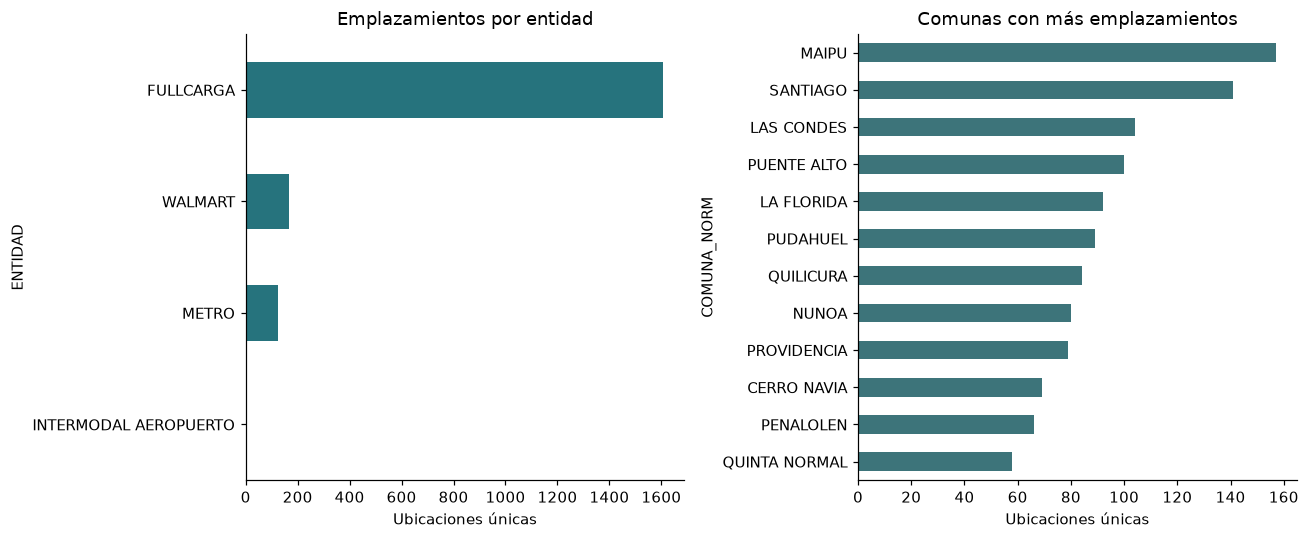

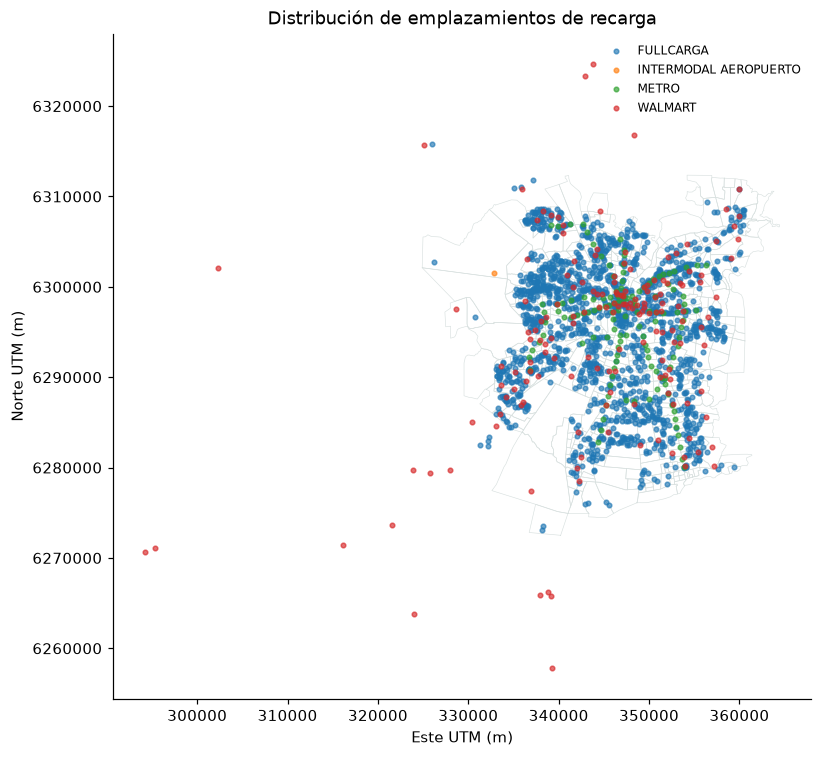

FULLCARGA concentra el 84.6% de las ubicaciones del catastro deduplicado.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
oferta_entidad = df_bip.ENTIDAD.replace('', 'Sin entidad').value_counts()
oferta_comuna = df_bip.COMUNA_NORM.replace('', 'Sin comuna').value_counts()
oferta_entidad.head(12).sort_values().plot.barh(ax=axes[0], color='#26737d')
oferta_comuna.head(12).sort_values().plot.barh(ax=axes[1], color='#3d747a')
axes[0].set(title='Emplazamientos por entidad', xlabel='Ubicaciones únicas')
axes[1].set(title='Comunas con más emplazamientos', xlabel='Ubicaciones únicas')
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 7))
for geometria in geometrias.values():
    for poligono in shapely.get_parts(geometria):
        x, y_poligono = poligono.exterior.xy
        ax.plot(x, y_poligono, color='#d8e0df', lw=.4, zorder=0)
nombre_entidad = df_bip.ENTIDAD.replace('', 'Sin entidad')
entidad_mapa = nombre_entidad.where(nombre_entidad.isin(oferta_entidad.head(4).index), 'Otras')
for entidad, puntos in df_bip.groupby(entidad_mapa):
    ax.scatter(puntos.ESTE, puntos.NORTE, s=9, alpha=.65, label=entidad)
ax.set(title='Distribución de emplazamientos de recarga', xlabel='Este UTM (m)', ylabel='Norte UTM (m)', aspect='equal')
ax.ticklabel_format(style='plain', useOffset=False)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

entidad_principal = oferta_entidad.index[0]
print(f'{entidad_principal} concentra el {oferta_entidad.iloc[0] / len(df_bip):.1%} de las ubicaciones del catastro deduplicado.')

### 2.2. Subidas por modo y diagnóstico comunal

La hoja `RESUMEN` del DTPM tabula subidas promedio para bus, metro y tren. Para conservar la comparación comunal del avance, se cruza la demanda laboral de todos los modos del tabulado con el inventario de recargas por comuna declarada. Los cortes aquí son **medianas**. Con demanda en el eje horizontal y oferta en el vertical, la combinación de alta demanda y baja oferta está abajo a la derecha. El cociente de subidas por punto describe presión agregada y queda sin valor cuando la comuna tiene cero puntos. La prioridad operativa se calcula después con distancias por paradero y P75.

,Laboral,Sábado,Domingo
Modo,,,
BUS,2512170.4,1308109,778684
METRO,2469425.4,1409869,778745
TREN,82233.6,48886,28115


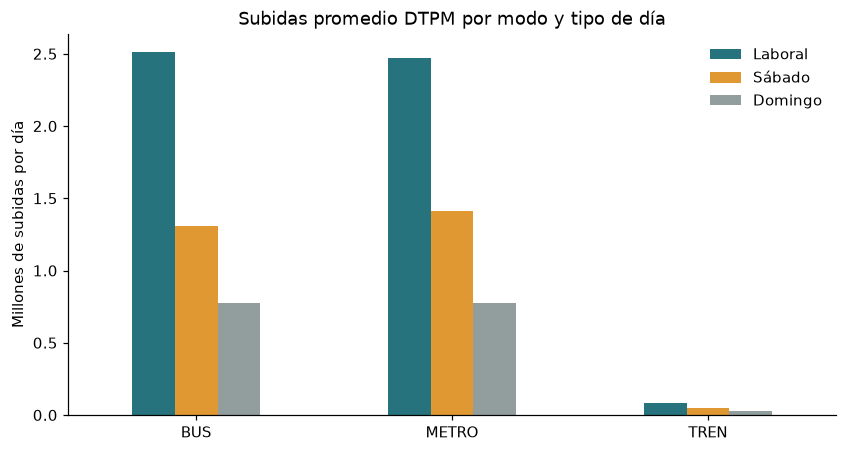

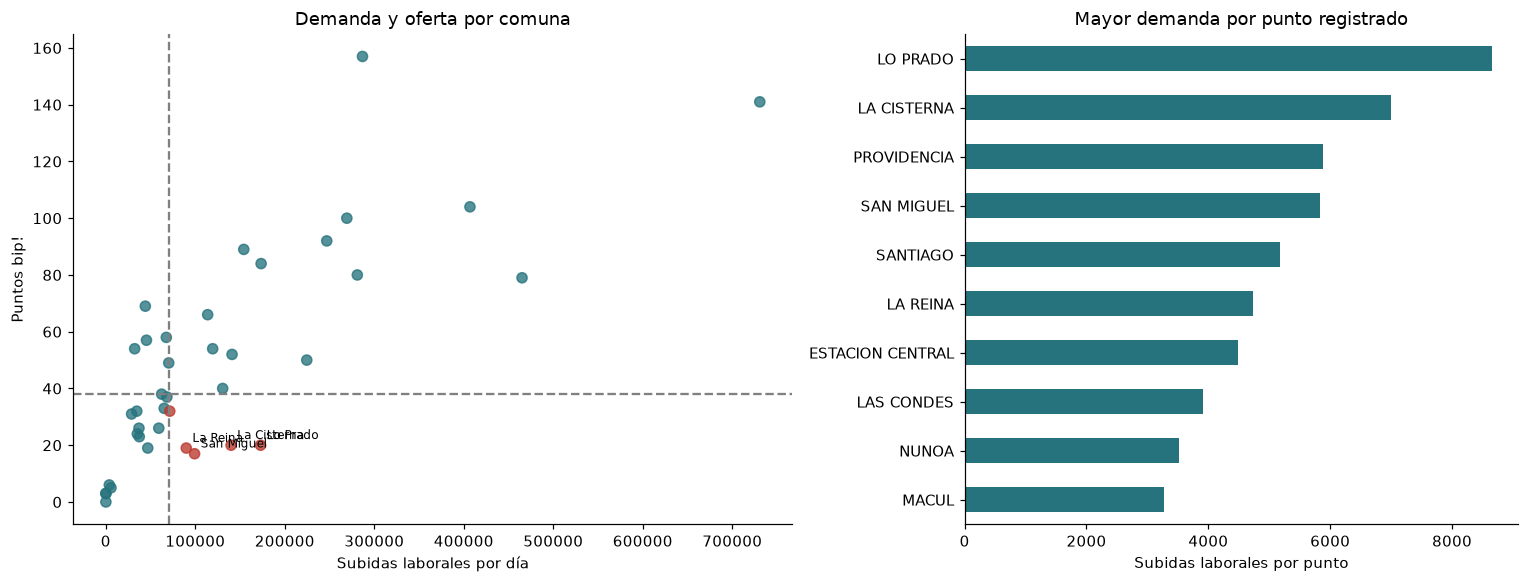

5 comunas cruzan el criterio exploratorio de alta demanda y baja oferta. 1 comunas carecen de puntos en el inventario declarado.


In [9]:
libro_dtpm = openpyxl.load_workbook(ruta_dtpm, read_only=True, data_only=True)
try:
    filas_resumen = list(libro_dtpm['RESUMEN'].values)
finally:
    libro_dtpm.close()
tipos_dia = ('Laboral', 'Sábado', 'Domingo')
assert tuple(filas_resumen[1][1:4]) == ('LABORAL','SABADO','DOMINGO')
assert tuple(filas_resumen[1][6:9]) == tuple(filas_resumen[1][1:4])
modos = pd.DataFrame(
    [(normalizar(f[0]), *f[1:4]) for f in filas_resumen[2:]
     if normalizar(f[0]) in {'BUS','METRO','TREN'}], columns=['Modo', *tipos_dia]
).set_index('Modo')
assert set(modos.index) == {'BUS','METRO','TREN'} and modos.index.is_unique
assert np.isclose(modos.loc['BUS','Laboral'], demanda_bus.SUBIDAS_LABORAL.sum())
display(modos.round(1))
ax = (modos / 1e6).plot.bar(figsize=(9, 4.5), color=['#26737d','#e09832','#929d9d'], rot=0)
ax.set(title='Subidas promedio DTPM por modo y tipo de día', ylabel='Millones de subidas por día', xlabel='')
ax.legend(frameon=False)
plt.show()

subidas_comuna = pd.DataFrame(
    [(normalizar(f[5]), f[6]) for f in filas_resumen[2:]
     if normalizar(f[5]) not in {'','-','TOTAL GENERAL','SIN COMUNA'}
     and isinstance(f[6], (int,float))], columns=['COMUNA','Subidas laborales']
).groupby('COMUNA')['Subidas laborales'].sum()
comunas = subidas_comuna.to_frame().join(oferta_comuna.rename('Puntos bip!'))
comunas['Puntos bip!'] = comunas['Puntos bip!'].fillna(0).astype(int)
comunas['Subidas por punto'] = comunas['Subidas laborales'] / comunas['Puntos bip!'].replace(0, np.nan)
corte_demanda = comunas['Subidas laborales'].median()
corte_oferta = comunas['Puntos bip!'].median()
alerta = comunas['Subidas laborales'].ge(corte_demanda) & comunas['Puntos bip!'].lt(corte_oferta)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={'width_ratios':[1.3,1]})
ax = axes[0]
ax.scatter(comunas['Subidas laborales'], comunas['Puntos bip!'], c=np.where(alerta, '#ba392d','#26737d'), alpha=.78, s=44)
ax.axvline(corte_demanda, color='gray', ls='--')
ax.axhline(corte_oferta, color='gray', ls='--')
ax.set(title='Demanda y oferta por comuna', xlabel='Subidas laborales por día', ylabel='Puntos bip!')
for nombre, fila in comunas.loc[alerta].nlargest(4, 'Subidas laborales').iterrows():
    ax.annotate(nombre.title(), (fila['Subidas laborales'], fila['Puntos bip!']), xytext=(4,4), textcoords='offset points', fontsize=8)
top_comunas = comunas['Subidas por punto'].dropna().nlargest(10).sort_values()
top_comunas.plot.barh(ax=axes[1], color='#26737d')
axes[1].set(title='Mayor demanda por punto registrado', xlabel='Subidas laborales por punto', ylabel='')
fig.tight_layout()
plt.show()
print(f'{alerta.sum()} comunas cruzan el criterio exploratorio de alta demanda y baja oferta. '
      f'{comunas["Puntos bip!"].eq(0).sum()} comunas carecen de puntos en el inventario declarado.')

### 2.3. Lectura de los viajes por bloques

`agregar_viajes` valida las siete fechas y lee únicamente cuatro campos de cada CSV. Conserva la suma por hora y por zona-día del flujo final. Esta versión agrega en el mismo recorrido las frecuencias de etapas y un histograma de distancias por tipo de día. La auditoría separa las fechas inválidas, los códigos ausentes y los valores inválidos de cada variable de EDA. Los viajes con fecha válida permanecen en la serie horaria. Un código ausente o inválido se marca como `-1` para el cruce zonal.

In [10]:
def agregar_viajes(carpeta, resultados):
    """Acumula conteos horarios, zonales y de EDA sin cargar identificadores."""
    archivos = {}
    for ruta in carpeta.rglob("*.viajes.csv"):
        coincidencia = re.fullmatch(r"(\d{4}-\d\d-\d\d)\.viajes\.csv", ruta.name)
        if ruta.is_file() and coincidencia:
            fecha = pd.Timestamp(coincidencia[1])
            if fecha in archivos:
                raise ValueError(f"Dos archivos de viajes para {fecha.date()}")
            archivos[fecha] = ruta
    fechas = pd.date_range("2026-04-11", "2026-04-17", freq="D")
    if set(archivos) != set(fechas):
        raise ValueError("Se esperan los siete CSV diarios del 11 al 17 de abril de 2026")

    horarios, zonas, control = [], [], []
    etapas_dia, distancias_dia = [], []
    bordes_km = np.r_[np.arange(0, 16), 20, 25, 30, 40, np.inf]
    columnas = ["tiempo_inicio_viaje", "zona_inicio_viaje", "n_etapas", "distancia_eucl"]
    for fecha in fechas:
        total_hora = np.zeros(24, dtype="int64")
        parciales = []
        n_leidas = sin_zona = sin_etapas = sin_distancia = 0
        etapas_por_dia = Counter()
        distancias_por_dia = np.zeros(len(bordes_km) - 1, dtype="int64")
        for bloque in pd.read_csv(archivos[fecha], sep="|", encoding="latin1",
                                 usecols=columnas, dtype="str", chunksize=300_000):
            n_leidas += len(bloque)
            tiempo = pd.to_datetime(bloque.tiempo_inicio_viaje, format="%Y-%m-%d %H:%M:%S",
                                    errors="coerce")
            validos = tiempo.ge(fecha) & tiempo.lt(fecha + pd.Timedelta(days=1))
            hora = tiempo[validos].dt.hour.to_numpy(dtype=int)
            total_hora += np.bincount(hora, minlength=24)
            codigo = pd.to_numeric(bloque.loc[validos, "zona_inicio_viaje"], errors="coerce")
            codigo = codigo.where(codigo.between(0, 9999) & codigo.mod(1).eq(0), -1).astype(int)
            sin_zona += int(codigo.eq(-1).sum())
            etapas = pd.to_numeric(bloque.loc[validos, "n_etapas"], errors="coerce")
            etapas_validas = etapas.ge(1) & etapas.mod(1).eq(0)
            sin_etapas += int((~etapas_validas).sum())
            etapas_por_dia.update(etapas[etapas_validas].astype(int).value_counts().to_dict())
            distancia = pd.to_numeric(bloque.loc[validos, "distancia_eucl"], errors="coerce") / 1000
            distancias_validas = distancia.ge(0) & np.isfinite(distancia)
            sin_distancia += int((~distancias_validas).sum())
            distancias_por_dia += np.histogram(distancia[distancias_validas], bins=bordes_km)[0]
            punta = ((hora >= 7) & (hora < 9)) | ((hora >= 17) & (hora < 20))
            datos = pd.DataFrame({"zona_777": codigo.to_numpy(), "viajes": 1, "punta": punta})
            parciales.append(datos.groupby("zona_777")[["viajes", "punta"]].sum())
        if not parciales or not total_hora.sum():
            raise ValueError(f"Sin viajes válidos el {fecha.date()}")
        zona_dia = pd.concat(parciales).groupby(level=0).sum().reset_index()
        zonas.append(zona_dia.assign(fecha=fecha))
        horarios.append(pd.DataFrame({"fecha_hora": pd.date_range(fecha, periods=24, freq="h"),
                                     "viajes_totales": total_hora}))
        tipo_dia = ("Sábado" if fecha.dayofweek == 5 else
                    "Domingo" if fecha.dayofweek == 6 else "Laboral")
        etapas_dia.extend({"fecha": fecha, "tipo_dia": tipo_dia, "etapas": k, "viajes": n}
                          for k, n in sorted(etapas_por_dia.items()))
        distancias_dia.extend({"fecha": fecha, "tipo_dia": tipo_dia,
                               "desde_km": izquierda, "hasta_km": derecha, "viajes": int(n)}
                              for izquierda, derecha, n in zip(bordes_km[:-1], bordes_km[1:], distancias_por_dia))
        assert sum(etapas_por_dia.values()) + sin_etapas == total_hora.sum()
        assert distancias_por_dia.sum() + sin_distancia == total_hora.sum()
        control.append({"zona_ausente_o_invalida": sin_zona, "etapas_invalidas": sin_etapas,
                        "distancia_invalida": sin_distancia,"fecha": fecha.date().isoformat(), "filas": n_leidas,
                        "viajes_validos": int(total_hora.sum()),
                        "fecha_invalida_o_fuera_del_dia": n_leidas - int(total_hora.sum())})
        print(f"{fecha.date()} · {int(total_hora.sum()):,} viajes con fecha válida", flush=True)

    horario = pd.concat(horarios, ignore_index=True)
    zonal_dia = pd.concat(zonas, ignore_index=True)
    assert horario.viajes_totales.sum() == zonal_dia.viajes.sum()
    horario.to_csv(resultados / "serie_temporal_viajes_horarios.csv", index=False)
    zonal_dia.to_csv(resultados / "viajes_por_zona_y_dia.csv", index=False)
    pd.DataFrame(control).to_csv(resultados / "auditoria_viajes.csv", index=False)
    return horario, zonal_dia, pd.DataFrame(control), pd.DataFrame(etapas_dia), pd.DataFrame(distancias_dia)

In [11]:
serie_df, viajes_diarios, auditoria_viajes, etapas_dia, distancias_dia = agregar_viajes(ruta_viajes, RESULTADOS)
display(auditoria_viajes.set_index('fecha').style.format(precision=0, thousands='.'))

2026-04-11 · 1,320,747 viajes con fecha válida
2026-04-12 · 691,101 viajes con fecha válida
2026-04-13 · 2,617,616 viajes con fecha válida
2026-04-14 · 2,664,062 viajes con fecha válida
2026-04-15 · 2,683,405 viajes con fecha válida
2026-04-16 · 2,668,412 viajes con fecha válida
2026-04-17 · 2,545,727 viajes con fecha válida


,zona_ausente_o_invalida,etapas_invalidas,distancia_invalida,filas,viajes_validos,fecha_invalida_o_fuera_del_dia
fecha,,,,,,
2026-04-11,210,0,0,1.320.747,1.320.747,0
2026-04-12,77,0,0,691.101,691.101,0
2026-04-13,464,0,0,2.617.616,2.617.616,0
2026-04-14,534,0,0,2.664.062,2.664.062,0
2026-04-15,444,0,0,2.683.405,2.683.405,0
2026-04-16,519,0,0,2.668.412,2.668.412,0
2026-04-17,410,0,0,2.545.727,2.545.727,0


### 2.4. Perfil horario, etapas y distancia de los viajes

El perfil horario usa días completos. La curva laboral promedia lunes a viernes y las curvas de fin de semana muestran un día cada una. Se mantienen las franjas de punta de 07:00–09:00 y 17:00–20:00. Dos o más etapas indican un transbordo inferido, que puede ocurrir dentro del mismo modo. `distancia_eucl` se convierte de metros a kilómetros y describe el desplazamiento en línea recta entre origen y destino. Es una variable distinta de la distancia al punto de recarga.

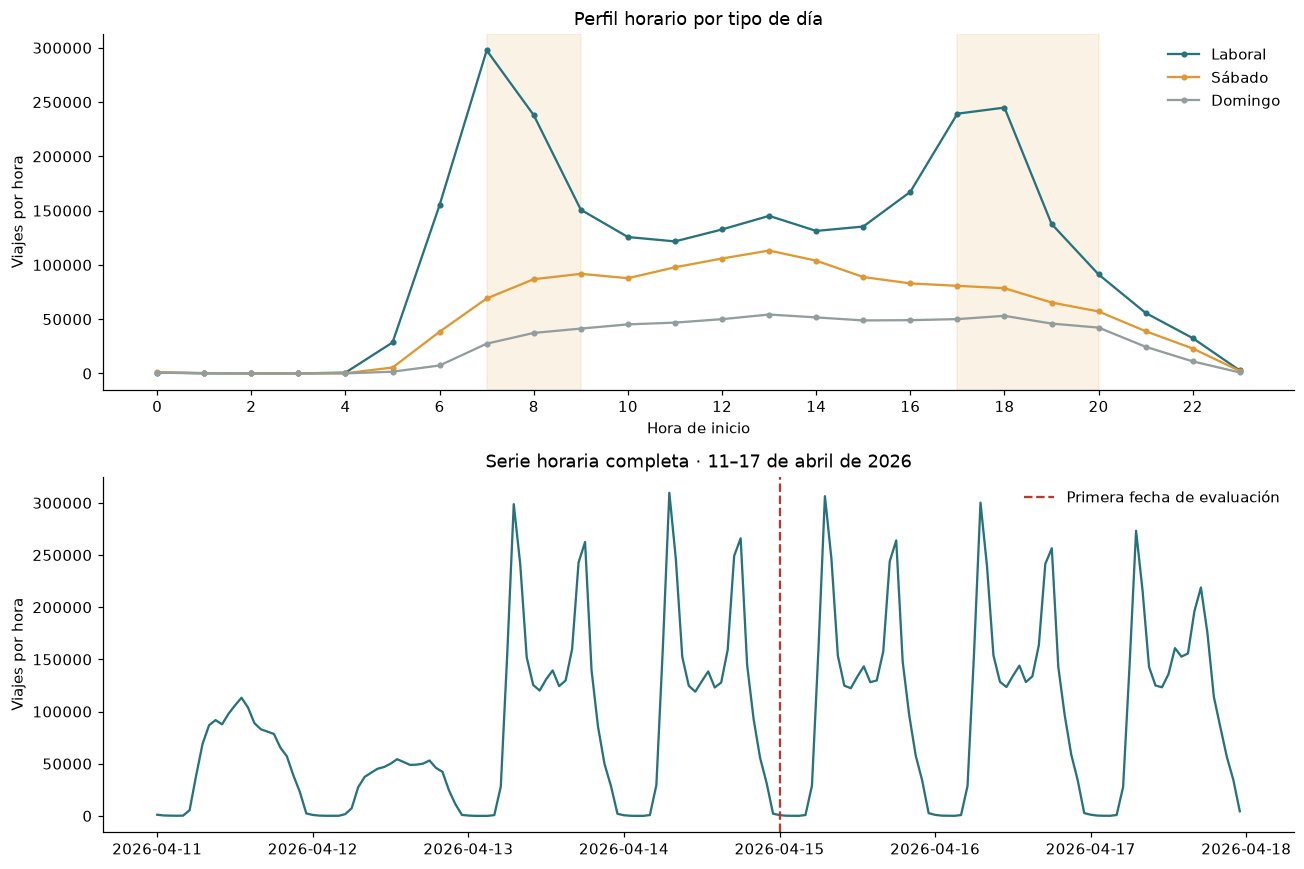

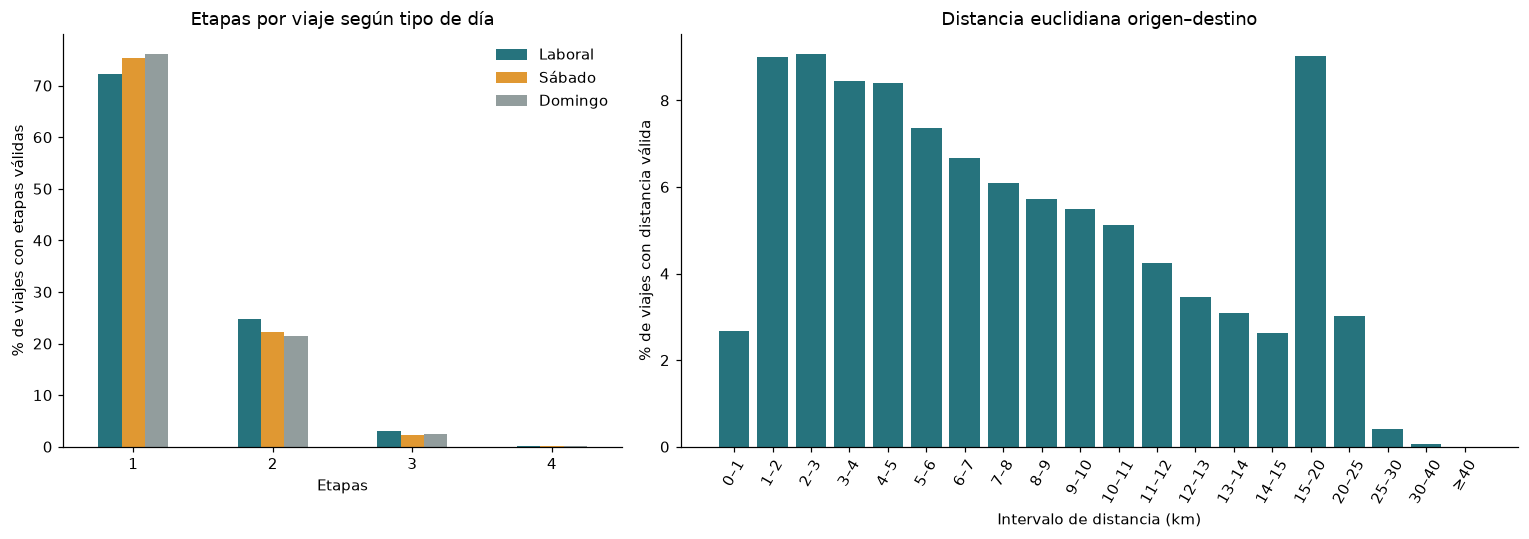

Viajes con información válida de etapas: 15.191.070. Proporción con 2 o más etapas: 27.3%.
Distancias válidas: 15.191.070. El gráfico muestra porcentajes por intervalo, incluidos los de ancho mayor y la cola abierta.


In [12]:
horas = serie_df.assign(hora=serie_df.fecha_hora.dt.hour, dia=serie_df.fecha_hora.dt.dayofweek)
horas['tipo_dia'] = np.select([horas.dia.eq(5), horas.dia.eq(6)], ['Sábado','Domingo'], default='Laboral')
perfiles_hora = horas.groupby(['hora','tipo_dia']).viajes_totales.mean().unstack()[list(tipos_dia)]
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
for tipo, color in zip(tipos_dia, ['#26737d','#e09832','#929d9d']):
    axes[0].plot(perfiles_hora.index, perfiles_hora[tipo], marker='o', ms=3, color=color, label=tipo)
for a, b in [(7,9),(17,20)]:
    axes[0].axvspan(a,b,color='#e09832',alpha=.12)
axes[0].set(xlabel='Hora de inicio', ylabel='Viajes por hora', title='Perfil horario por tipo de día', xticks=range(0,24,2))
axes[0].legend(frameon=False)
axes[1].plot(serie_df.fecha_hora, serie_df.viajes_totales, color='#26737d')
axes[1].axvline(pd.Timestamp('2026-04-15'), ls='--', color='#ba392d', label='Primera fecha de evaluación')
axes[1].set(ylabel='Viajes por hora', title='Serie horaria completa · 11–17 de abril de 2026')
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

tabla_etapas = etapas_dia.groupby(['etapas','tipo_dia']).viajes.sum().unstack(fill_value=0)[list(tipos_dia)]
tabla_dist = distancias_dia.groupby(['desde_km','hasta_km'], as_index=False).viajes.sum()
tabla_dist['Intervalo'] = [f'{a:g}–{b:g}' if np.isfinite(b) else f'≥{a:g}'
                           for a,b in zip(tabla_dist.desde_km, tabla_dist.hasta_km)]
fig, axes = plt.subplots(1,2,figsize=(14,5), gridspec_kw={'width_ratios':[1,1.5]})
(100 * tabla_etapas / tabla_etapas.sum()).plot.bar(ax=axes[0], rot=0, color=['#26737d','#e09832','#929d9d'])
axes[0].set(title='Etapas por viaje según tipo de día', xlabel='Etapas', ylabel='% de viajes con etapas válidas')
axes[0].legend(frameon=False)
axes[1].bar(tabla_dist.Intervalo, 100 * tabla_dist.viajes / tabla_dist.viajes.sum(), color='#26737d')
axes[1].set(title='Distancia euclidiana origen–destino', xlabel='Intervalo de distancia (km)', ylabel='% de viajes con distancia válida')
axes[1].tick_params(axis='x', labelrotation=60)
fig.tight_layout()
plt.show()
total_etapas = tabla_etapas.to_numpy().sum()
print(f'Viajes con información válida de etapas: {numero(total_etapas)}. '
      f'Proporción con 2 o más etapas: {tabla_etapas.loc[tabla_etapas.index >= 2].to_numpy().sum()/total_etapas:.1%}.')
print(f'Distancias válidas: {numero(tabla_dist.viajes.sum())}. '
      f'El gráfico muestra porcentajes por intervalo, incluidos los de ancho mayor y la cola abierta.')

## 3. Accesibilidad y cuatro cuadrantes

Cada paradero se compara con **todo** el catastro, incluso con puntos de una zona vecina. La distancia mínima y los radios se calculan en línea recta UTM 19S. Para cada zona se calcula el porcentaje de subidas en paraderos sin recarga a 300 o 500 m y la distancia media ponderada por subidas. El número de puntos **dentro** del polígono se informa como un atributo separado.

Se conserva la regla del avance para paraderos. Demanda alta desde P75 de subidas. Distancia alta desde P75 de distancia. En zonas, demanda alta corresponde al P75 de viajes registrados por día laboral y brecha alta al P75 del porcentaje de subidas sin recarga a 500 m. Los P75 zonales se calculan sobre zonas con viajes y con subidas de bus enlazadas. Las otras quedan como «Sin datos comparables». Los porcentajes de punta usan 07:00–09:00 y 17:00–20:00, con extremo final excluido.

**Cómo funciona `construir_zonas`.** Parte del universo de polígonos y agrega los viajes de origen de lunes a viernes y su proporción en punta. Une el número de puntos físicamente dentro de cada polígono. Calcula por separado la distancia media y la brecha a 300 y 500 m ponderadas por subidas de bus. Una zona sin subidas enlazadas queda sin proporción calculable.

In [13]:
def construir_zonas(geometrias, comunas, viajes_diarios, maestro, df_bip):
    universo = pd.DataFrame({"zona_777": list(geometrias), "comuna_cartografica": list(comunas[z] for z in geometrias)})
    laborales = viajes_diarios.loc[viajes_diarios.fecha.dt.dayofweek < 5]
    acumulado = laborales.groupby("zona_777", as_index=False)[["viajes", "punta"]].sum()
    zonas = universo.merge(acumulado, on="zona_777", how="left", validate="1:1")
    zonas[["viajes", "punta"]] = zonas[["viajes", "punta"]].fillna(0).astype(int)
    dias = laborales.fecha.nunique()
    zonas["viajes_laborales_dia"] = zonas.viajes / dias
    zonas["pct_viajes_punta"] = 100 * zonas.punta.div(zonas.viajes.where(zonas.viajes.gt(0)))
    oferta = df_bip.groupby("zona_777").size().rename("puntos_bip_internos")
    zonas = zonas.join(oferta, on="zona_777")
    zonas["puntos_bip_internos"] = zonas.puntos_bip_internos.fillna(0).astype(int)

    acceso = maestro.assign(distancia_ponderada=maestro.SUBIDAS_LABORAL * maestro.distancia_min_bip_m)
    for radio in (300, 500):
        acceso[f"subidas_sin_{radio}m"] = acceso.SUBIDAS_LABORAL.where(acceso[f"bip_en_{radio}m"].eq(0), 0)
    paradas = acceso.groupby("zona_777").agg(
        paraderos_bus=("PARADA", "size"), subidas_bus_dia=("SUBIDAS_LABORAL", "sum"),
        distancia_ponderada=("distancia_ponderada", "sum"),
        subidas_sin_300m=("subidas_sin_300m", "sum"), subidas_sin_500m=("subidas_sin_500m", "sum"))
    zonas = zonas.join(paradas, on="zona_777")
    zonas["paraderos_bus"] = zonas.paraderos_bus.fillna(0).astype(int)
    zonas["distancia_media_ponderada_m"] = zonas.distancia_ponderada / zonas.subidas_bus_dia
    for radio in (300, 500):
        zonas[f"pct_subidas_sin_{radio}m"] = 100 * zonas[f"subidas_sin_{radio}m"] / zonas.subidas_bus_dia
    return zonas.drop(columns="distancia_ponderada")

In [14]:
arbol_bip = cKDTree(df_bip[['ESTE','NORTE']].to_numpy())
xy = maestro[['X_UTM','Y_UTM']].to_numpy()
maestro['distancia_min_bip_m'], indices_bip = arbol_bip.query(xy)
for radio in (RADIO_CERCANO_M, RADIO_AISLAMIENTO_M):
    maestro[f'bip_en_{radio}m'] = arbol_bip.query_ball_point(xy, radio, return_length=True)
maestro['bip_mas_cercano'] = df_bip.iloc[indices_bip].ENTIDAD.to_numpy()
trans = Transformer.from_crs(32719, 4326, always_xy=True)
maestro['LON'], maestro['LAT'] = trans.transform(*xy.T)
df_bip['LON'], df_bip['LAT'] = trans.transform(df_bip.ESTE.to_numpy(), df_bip.NORTE.to_numpy())
df_bip.to_csv(RESULTADOS / 'puntos_bip_consolidados.csv', index=False)

COLORES = {'Prioridad crítica':'#ba392d', 'Prioridad de accesibilidad':'#de9e3b',
           'Alta demanda con recarga próxima':'#26737d', 'Menor prioridad':'#aebfc0',
           'Sin datos comparables':'#e8ebea'}

def cuadrantes(alta_demanda, alta_brecha):
    return np.select([alta_demanda & alta_brecha, alta_brecha, alta_demanda],
                     list(COLORES)[:3], default='Menor prioridad')

# La suma de fracciones decimales puede quedar apenas por debajo de un empate.
maestro["SUBIDAS_LABORAL"] = maestro.SUBIDAS_LABORAL.round(6)
p75_demanda = maestro.SUBIDAS_LABORAL.quantile(.75)
p75_distancia = maestro.distancia_min_bip_m.quantile(.75)
maestro['prioridad_territorial'] = cuadrantes(maestro.SUBIDAS_LABORAL.ge(p75_demanda),
                                             maestro.distancia_min_bip_m.ge(p75_distancia))
maestro['indice_estres'] = maestro.SUBIDAS_LABORAL * maestro.distancia_min_bip_m / 1000
maestro['dist_centro_km'] = np.hypot(maestro.X_UTM-346900, maestro.Y_UTM-6300100) / 1000
maestro['paraderos_en_500m'] = cKDTree(xy).query_ball_point(xy, 500, return_length=True) - 1
maestro.to_csv(RESULTADOS / 'matriz_paraderos_modelado.csv', index=False)

zonas = construir_zonas(geometrias, comunas_shape, viajes_diarios, maestro, df_bip)
con_datos = zonas.viajes.gt(0) & zonas.subidas_bus_dia.gt(0)
umbral_viajes = zonas.loc[con_datos, 'viajes_laborales_dia'].quantile(.75)
umbral_brecha = zonas.loc[con_datos, 'pct_subidas_sin_500m'].quantile(.75)
zonas['cuadrante'] = 'Sin datos comparables'
zonas.loc[con_datos, 'cuadrante'] = cuadrantes(
    zonas.loc[con_datos, 'viajes_laborales_dia'].ge(umbral_viajes),
    zonas.loc[con_datos, 'pct_subidas_sin_500m'].ge(umbral_brecha))
criticas = zonas.cuadrante.eq('Prioridad crítica')
sin_carga = zonas.puntos_bip_internos.eq(0)
fuera_zona = viajes_diarios.loc[~viajes_diarios.zona_777.isin(geometrias), 'viajes'].sum()
print(f'Viajes con fecha válida: {numero(serie_df.viajes_totales.sum())}. Sin código en el mapa: {numero(fuera_zona)}.')
print(f'Zonas comparables: {con_datos.sum()} de {len(zonas)}. P75: {umbral_viajes:.1f} viajes/día y {umbral_brecha:.1f}% de subidas sin cobertura a 500 m.')
display(pd.concat([maestro.prioridad_territorial.value_counts().rename('Paraderos BUS'),
                   zonas.cuadrante.value_counts().rename('Zonas 777')], axis=1).fillna(0).astype(int))

Viajes con fecha válida: 15.191.070. Sin código en el mapa: 34.553.
Zonas comparables: 793 de 803. P75: 2406.0 viajes/día y 13.4% de subidas sin cobertura a 500 m.


,Paraderos BUS,Zonas 777
Menor prioridad,6383,421
Alta demanda con recarga próxima,2563,173
Prioridad de accesibilidad,2561,173
Prioridad crítica,422,26
Sin datos comparables,0,10


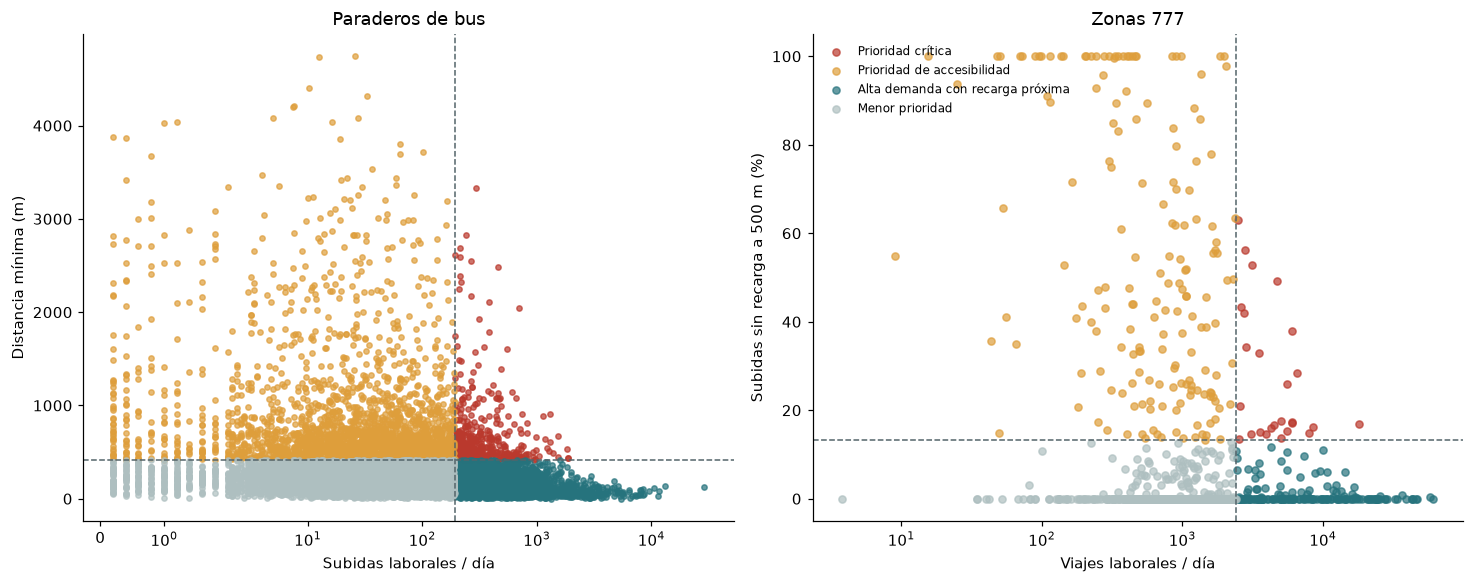

,radio_m,paraderos_sin_recarga,subidas_dia_sin_recarga,pct_subidas
0,300,4884,503883.6,20.1
1,500,2089,177631.4,7.1


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4))
for ax, tabla, grupo, x, y, cortes, tit, ejes in [
    (axes[0], maestro, 'prioridad_territorial', 'SUBIDAS_LABORAL', 'distancia_min_bip_m',
     (p75_demanda, p75_distancia), 'Paraderos de bus', ('Subidas laborales / día', 'Distancia mínima (m)')),
    (axes[1], zonas[con_datos], 'cuadrante', 'viajes_laborales_dia', 'pct_subidas_sin_500m',
     (umbral_viajes, umbral_brecha), 'Zonas 777', ('Viajes laborales / día', 'Subidas sin recarga a 500 m (%)')),
]:
    for perfil, color in COLORES.items():
        sub = tabla.loc[tabla[grupo].eq(perfil)]
        if not sub.empty:
            ax.scatter(sub[x], sub[y], s=12 if ax is axes[0] else 22, color=color, alpha=.7, label=perfil)
    ax.set(xscale='symlog', xlabel=ejes[0], ylabel=ejes[1], title=tit)
    ax.axvline(cortes[0], ls='--', c='#53646a', lw=1)
    ax.axhline(cortes[1], ls='--', c='#53646a', lw=1)
axes[1].legend(loc='upper left', fontsize=8, frameon=False)
guardar_figura(fig, '03_matriz_prioridad.png')

resultados_radios = pd.DataFrame([
    {'radio_m': radio, 'paraderos_sin_recarga': int(maestro[f'bip_en_{radio}m'].eq(0).sum()),
     'subidas_dia_sin_recarga': maestro.loc[maestro[f'bip_en_{radio}m'].eq(0), 'SUBIDAS_LABORAL'].sum()}
    for radio in (300, 500)])
resultados_radios['pct_subidas'] = 100 * resultados_radios.subidas_dia_sin_recarga / maestro.SUBIDAS_LABORAL.sum()
resultados_radios.to_csv(RESULTADOS / 'sensibilidad_radios.csv', index=False)
display(resultados_radios.round(1))

### Cómo leer esta matriz frente al avance

| Figura | Unidad | Eje X | Eje Y | Cortes y posición crítica |
|---|---|---|---|---|
| EDA comunal del avance e integral | Comuna | Subidas laborales | Puntos bip! registrados | Medianas. Alta demanda y baja oferta quedan abajo a la derecha. |
| Matriz del avance | Paradero del diccionario histórico | Distancia mínima al bip! | Subidas laborales (escala logarítmica) | P75 de 390,38 m y 278,73 subidas/día. Prioridad crítica arriba a la derecha. |
| Panel izquierdo integral | Paradero BUS DTPM enlazado a GTFS | Subidas laborales (escala simétrica logarítmica) | Distancia mínima al bip! (m) | P75 de 191,80 subidas/día y 414,53 m. Prioridad crítica arriba a la derecha. |
| Panel derecho integral | Zona 777 | Inicios de viaje laborales (escala simétrica logarítmica) | % de subidas de bus en paraderos sin bip! a 500 m | P75 de 2.406 viajes/día y 13,37 %. Prioridad crítica arriba a la derecha. |

El intercambio de ejes, el cambio de escala y el límite visual de 2.200 m del avance explican parte de la diferencia en la forma del panel de paraderos. La regla sigue marcando como críticos los registros que superan o igualan ambos P75. Los cortes se recalculan sobre la base de cada versión. El avance usó subidas y bajadas del diccionario histórico y reportó 375 de 10.754 registros críticos. La versión integral usa subidas BUS DTPM de abril de 2026 enlazadas a coordenadas GTFS y marca 422 de 11.929. Las 26 zonas críticas se calculan por separado entre las 793 zonas con demanda y acceso comparables.

**Por qué se agregó GTFS.** El diccionario histórico permitía ubicar por código interno el 58,03 % de las subidas laborales DTPM. El GTFS vincula el código público de DTPM con coordenadas de paraderos y describe su oferta programada de rutas de bus. El cruce alcanzó el 99,94 % de las subidas. Las subidas siguen viniendo de DTPM y los inicios de viaje de ADATRAP. El GTFS entró en vigencia el 18 de abril, un día después de la ventana de demanda, por lo que su ubicación y oferta se usan como aproximación al período observado.

### 3.1. Distancias y cobertura del catastro

El histograma muestra paraderos por distancia al punto más cercano. La curva acumulada compara dos denominadores. Cada paradero pesa uno en la primera curva y pesa sus subidas laborales en la segunda. Se muestran las dos curvas porque contar paraderos y contar subidas describe impactos distintos.

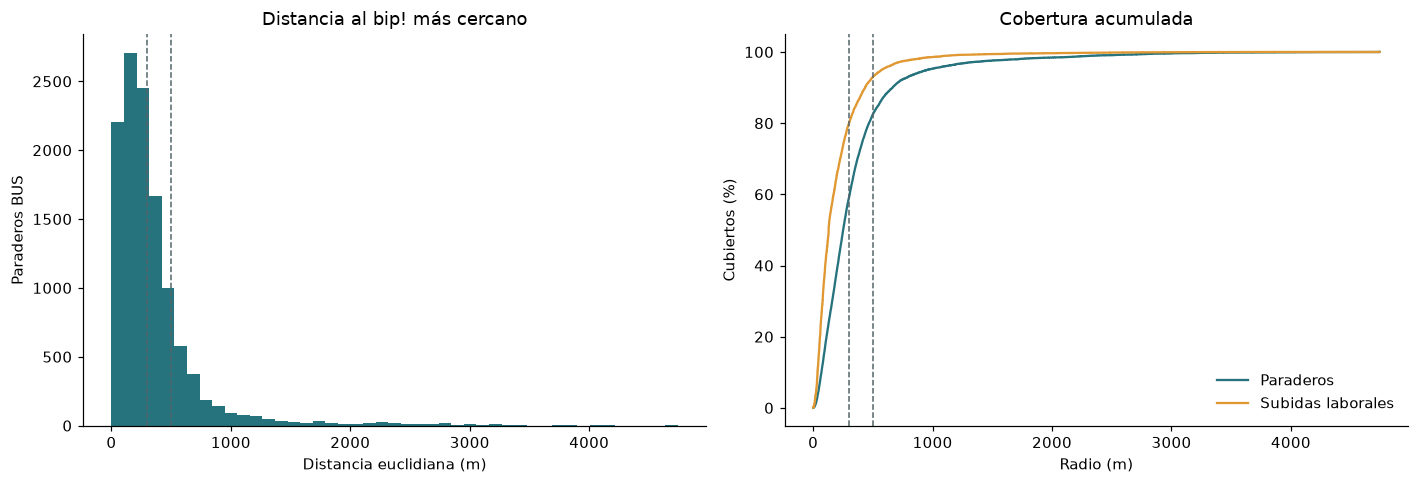

Distancia mediana por paradero: 251,1 m.


In [16]:
orden_distancia = maestro.sort_values('distancia_min_bip_m')
distancias = orden_distancia.distancia_min_bip_m.to_numpy()
pesos_subidas = orden_distancia.SUBIDAS_LABORAL.to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(distancias, bins=45, color='#26737d')
axes[0].set(title='Distancia al bip! más cercano', xlabel='Distancia euclidiana (m)', ylabel='Paraderos BUS')
axes[1].step(distancias, 100*np.arange(1, len(distancias)+1)/len(distancias), label='Paraderos', color='#26737d', where='post')
axes[1].step(distancias, 100*np.cumsum(pesos_subidas)/pesos_subidas.sum(), label='Subidas laborales', color='#e09832', where='post')
axes[1].set(title='Cobertura acumulada', xlabel='Radio (m)', ylabel='Cubiertos (%)')
axes[1].legend(frameon=False)
for ax in axes:
    for radio in (RADIO_CERCANO_M, RADIO_AISLAMIENTO_M):
        ax.axvline(radio, color='#53646a', ls='--', lw=1)
fig.tight_layout()
plt.show()
print(f'Distancia mediana por paradero: {numero(np.median(distancias), 1)} m.')

### 3.2. Sensibilidad de la prioridad zonal

Se compara el diagnóstico principal con dos escenarios. El primero recalcula el P75 de brecha a 300 m. El segundo usa subidas de bus como demanda y mantiene 500 m. Cada escenario conserva las mismas zonas comparables y recalcula el P75 de las variables que cambian. La intersección indica cuántas zonas también son críticas en el escenario principal.

In [17]:
comparables = zonas.loc[con_datos]
principal = set(zonas.loc[criticas, 'zona_777'])
filas_sensibilidad = []
for nombre, demanda, brecha in [
    ('Viajes de origen · 500 m', 'viajes_laborales_dia','pct_subidas_sin_500m'),
    ('Viajes de origen · 300 m', 'viajes_laborales_dia','pct_subidas_sin_300m'),
    ('Subidas de bus · 500 m', 'subidas_bus_dia','pct_subidas_sin_500m'),
]:
    corte_d, corte_b = comparables[demanda].quantile(.75), comparables[brecha].quantile(.75)
    selec = comparables[demanda].ge(corte_d) & comparables[brecha].ge(corte_b)
    ids = set(comparables.loc[selec, 'zona_777'])
    filas_sensibilidad.append((nombre, corte_d, corte_b, len(ids), len(ids & principal)))
sensibilidad_zonal = pd.DataFrame(filas_sensibilidad, columns=[
    'Escenario','P75 de demanda diaria','P75 de brecha (%)','Zonas críticas','En común con el principal'])
display(sensibilidad_zonal.round(2))

,Escenario,P75 de demanda diaria,P75 de brecha (%),Zonas críticas,En común con el principal
0,Viajes de origen · 500 m,2406.0,13.37,26,26
1,Viajes de origen · 300 m,2406.0,54.81,11,9
2,Subidas de bus · 500 m,3539.8,13.37,21,14


## 4. PCA y K-Means en Zona 777

El PCA se ajusta sobre atributos estandarizados. Los volúmenes y conteos de oferta se transforman con `log1p` para limitar el peso de valores extremos. Se usa una variable de cobertura (500 m) en el modelo para evitar darle doble peso junto con 300 m. Las cargas del PCA describen contribuciones a la variación de los datos. El clustering se ajusta en las cinco variables transformadas y se proyecta en dos componentes para la visualización.

Se prueba K-Means para k de 2 a 8 y se elige la mayor silueta. Se usa la curva del codo como diagnóstico complementario. Un grupo se caracteriza como de alta demanda y alta brecha si las medianas de sus zonas cruzan ambos P75. Se reporta también el grupo con mayor mediana de brecha. La matriz de cuadrantes identifica las zonas críticas individuales aunque sus clústeres tengan medianas por debajo de alguno de los cortes. El CSV de viajes carece de un campo de espera con correspondencia inequívoca en el diccionario local, así que la espera no se incluye.

In [18]:
variables_cluster = ['viajes_laborales_dia', 'pct_viajes_punta', 'puntos_bip_internos',
                     'distancia_media_ponderada_m', 'pct_subidas_sin_500m']
base_cluster = zonas.loc[con_datos, variables_cluster].copy()
for col in ['viajes_laborales_dia', 'puntos_bip_internos']:
    base_cluster[col] = np.log1p(base_cluster[col])
estandarizadas = StandardScaler().fit_transform(base_cluster)
pca = PCA(n_components=2)
coordenadas_pca = pca.fit_transform(estandarizadas)
cargas_pca = pd.DataFrame(pca.components_.T, index=variables_cluster, columns=['PC1','PC2'])
cargas_pca.to_csv(RESULTADOS / 'cargas_pca_zona777.csv', index_label='variable')

diagnosticos, etiquetas = [], {}
with threadpool_limits(limits=1):
    for k in range(2, 9):
        km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=30).fit(estandarizadas)
        etiquetas[k] = km.labels_
        diagnosticos.append({'k': k, 'inercia': km.inertia_, 'silueta': silhouette_score(estandarizadas, km.labels_)})
tabla_k = pd.DataFrame(diagnosticos)
tabla_k.to_csv(RESULTADOS / 'evaluacion_kmeans_zona777.csv', index=False)
k_optimo = int(tabla_k.loc[tabla_k.silueta.idxmax(), 'k'])
zonas['cluster'] = pd.Series(pd.NA, index=zonas.index, dtype='Int64')
zonas.loc[con_datos, 'cluster'] = etiquetas[k_optimo]
zonas.loc[con_datos, ['PC1','PC2']] = coordenadas_pca
perfiles = zonas.loc[con_datos].groupby('cluster')[variables_cluster].median()
perfiles['zonas'] = zonas.loc[con_datos].groupby('cluster').size()
perfil_mayor_brecha = int(perfiles.pct_subidas_sin_500m.idxmax())
perfiles['alta_demanda_y_brecha'] = perfiles.viajes_laborales_dia.ge(umbral_viajes) & perfiles.pct_subidas_sin_500m.ge(umbral_brecha)
nombres = {int(i): f'Perfil {i}' for i in perfiles.index}
nombres[perfil_mayor_brecha] += ' · mayor brecha mediana'
zonas['perfil'] = zonas.cluster.map(nombres).fillna('Sin datos comparables')
perfiles['perfil'] = perfiles.index.map(nombres)
perfiles['zonas_criticas'] = zonas.loc[criticas].groupby('cluster').size().reindex(perfiles.index, fill_value=0)
perfiles.to_csv(RESULTADOS / 'perfiles_zona777.csv')
zonas.to_csv(RESULTADOS / 'diagnostico_zona777.csv', index=False)
display(perfiles.round(1), cargas_pca.round(3))
print(f'PCA explica {pca.explained_variance_ratio_.sum():.1%} en dos componentes. Silueta elegida: {tabla_k.silueta.max():.3f}.')

,viajes_laborales_dia,pct_viajes_punta,puntos_bip_internos,distancia_media_ponderada_m,pct_subidas_sin_500m,zonas,alta_demanda_y_brecha,perfil,zonas_criticas
cluster,,,,,,,,,
0,1366.4,41.3,2.0,193.9,0.0,683,False,Perfil 0,23
1,442.1,42.5,0.0,603.1,70.7,110,False,Perfil 1 · mayor brecha mediana,3


,PC1,PC2
viajes_laborales_dia,-0.397,0.495
pct_viajes_punta,-0.045,0.813
puntos_bip_internos,-0.484,0.010
distancia_media_ponderada_m,0.554,0.204
pct_subidas_sin_500m,0.548,0.228


PCA explica 75.4% en dos componentes. Silueta elegida: 0.474.


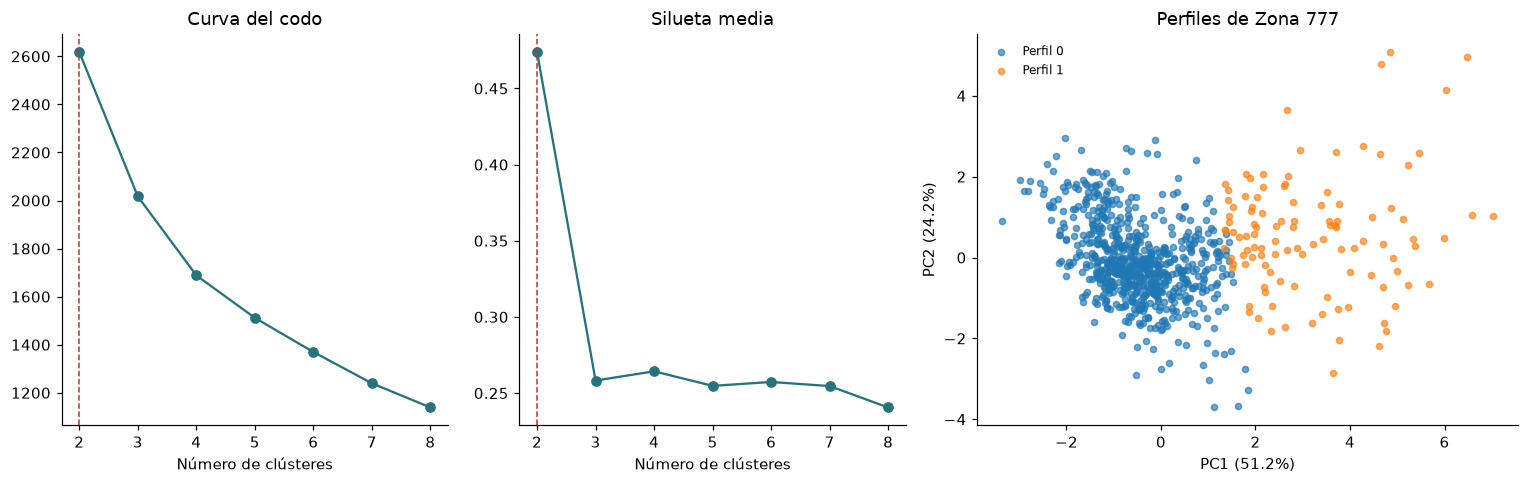

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), gridspec_kw={'width_ratios':[1, 1, 1.4]})
for ax, col, titulo in zip(axes[:2], ['inercia','silueta'], ['Curva del codo','Silueta media']):
    ax.plot(tabla_k.k, tabla_k[col], marker='o', color='#26737d')
    ax.axvline(k_optimo, ls='--', color='#ba392d', lw=1)
    ax.set(xlabel='Número de clústeres', title=titulo)
for id_perfil, sub in zonas.loc[con_datos].groupby('cluster'):
    axes[2].scatter(sub.PC1, sub.PC2, s=16, alpha=.65, label=f'Perfil {id_perfil}')
axes[2].legend(frameon=False, fontsize=8)
axes[2].set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})',
            ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})', title='Perfiles de Zona 777')
guardar_figura(fig, '05_pca_clustering.png')

### 4.1. Varianza, cargas y biplot

El *scree plot* muestra qué fracción de varianza aporta cada componente. En el mapa de cargas, el valor absoluto indica cuánto pesa cada variable estandarizada en la dirección del componente. El signo depende de la orientación elegida para el eje. Las flechas del biplot usan una única escala visual y muestran la dirección de las cargas en PC1 y PC2.

Se adaptó el cálculo de varianza individual y acumulada de la sección de PCA de la Actividad 1. Los atributos y la unidad de análisis corresponden a las zonas de Santiago.

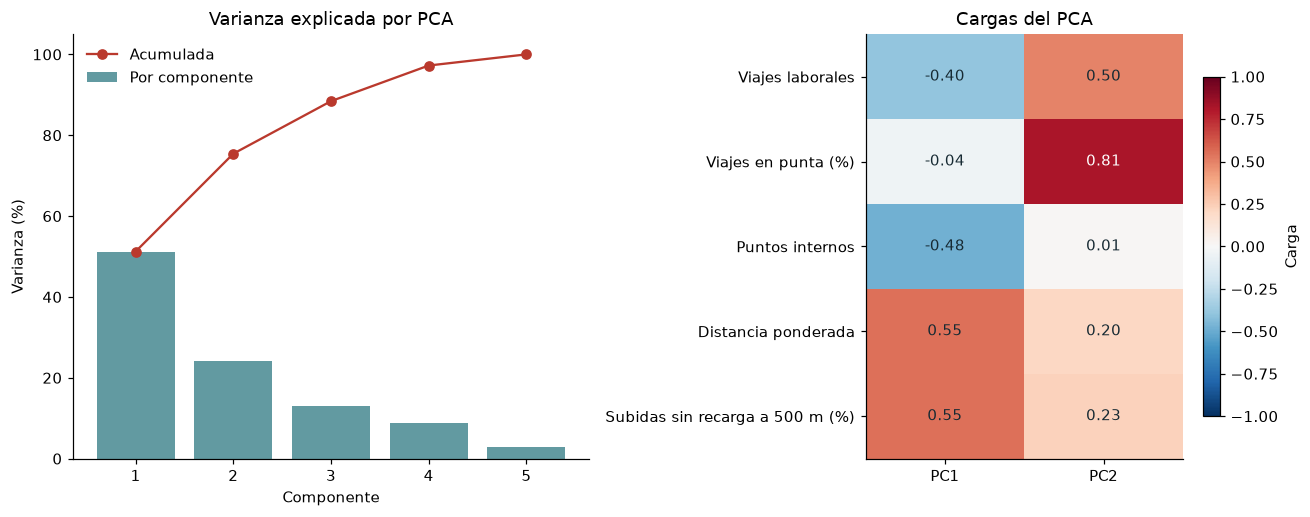

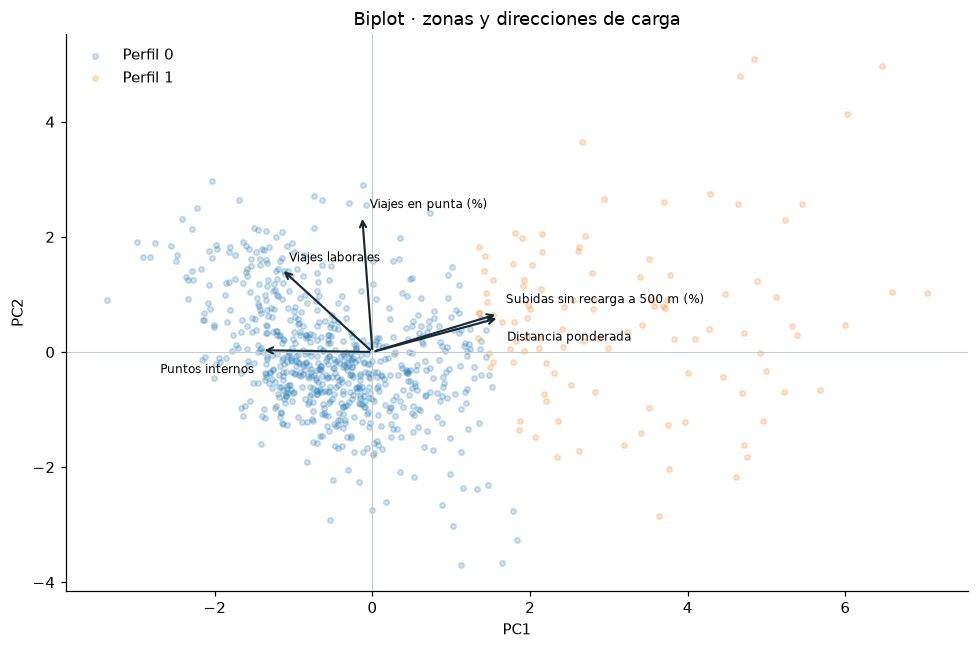

In [20]:
nombres_variables = ['Viajes laborales','Viajes en punta (%)','Puntos internos',
                     'Distancia ponderada','Subidas sin recarga a 500 m (%)']
pca_completo = PCA().fit(estandarizadas)
# Adaptado de la Actividad 1, sección de varianza explicada.
exp_var = pca_completo.explained_variance_ratio_
cum_exp = np.cumsum(exp_var)
varianza = 100 * exp_var
componentes = np.arange(1, len(varianza)+1)
fig, axes = plt.subplots(1,2,figsize=(12,4.8),gridspec_kw={'width_ratios':[1.3,1]})
axes[0].bar(componentes, varianza, alpha=.72, color='#26737d', label='Por componente')
axes[0].plot(componentes, 100 * cum_exp, marker='o', color='#ba392d', label='Acumulada')
axes[0].set(title='Varianza explicada por PCA', xlabel='Componente', ylabel='Varianza (%)', xticks=componentes)
axes[0].legend(frameon=False)
im = axes[1].imshow(cargas_pca, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
axes[1].set(xticks=[0,1], xticklabels=['PC1','PC2'], yticks=np.arange(len(nombres_variables)), yticklabels=nombres_variables, title='Cargas del PCA')
for fila, valores in enumerate(cargas_pca.to_numpy()):
    for col, carga in enumerate(valores):
        axes[1].text(col, fila, f'{carga:.2f}', ha='center', va='center', color='white' if abs(carga)>.6 else '#172a33')
fig.colorbar(im, ax=axes[1], shrink=.8, label='Carga')
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 6))
for grupo, sub in zonas.loc[con_datos].groupby('cluster'):
    ax.scatter(sub.PC1, sub.PC2, alpha=.22, s=13, label=f'Perfil {grupo}')
ax.axhline(0, color='#c2cbcb', lw=.7)
ax.axvline(0, color='#c2cbcb', lw=.7)
escala_flechas = np.quantile(np.linalg.norm(coordenadas_pca, axis=1), .90)
desplazamientos = [(5, 5), (5, 5), (-5, -15), (5, -15), (5, 7)]
for etiqueta, vector, offset in zip(nombres_variables, cargas_pca.to_numpy(), desplazamientos):
    extremo = vector * escala_flechas
    ax.annotate('', xy=extremo, xytext=(0,0), arrowprops={'arrowstyle':'->','color':'#172a33','lw':1.4})
    ax.annotate(etiqueta, extremo, xytext=offset, textcoords='offset points', fontsize=8,
                ha='right' if offset[0] < 0 else 'left')
ax.set(title='Biplot · zonas y direcciones de carga', xlabel='PC1', ylabel='PC2')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### 4.2. Siluetas individuales y estabilidad descriptiva al cambiar k

La silueta individual mide si cada zona está más próxima al grupo asignado que al grupo alternativo más cercano en el espacio estandarizado. Los valores negativos indican solapamiento. La proyección para varios `k` usa el mismo plano PCA y permite ver cambios de asignación. Los boxplots resumen atributos en su escala original. Los números de clúster son etiquetas arbitrarias.

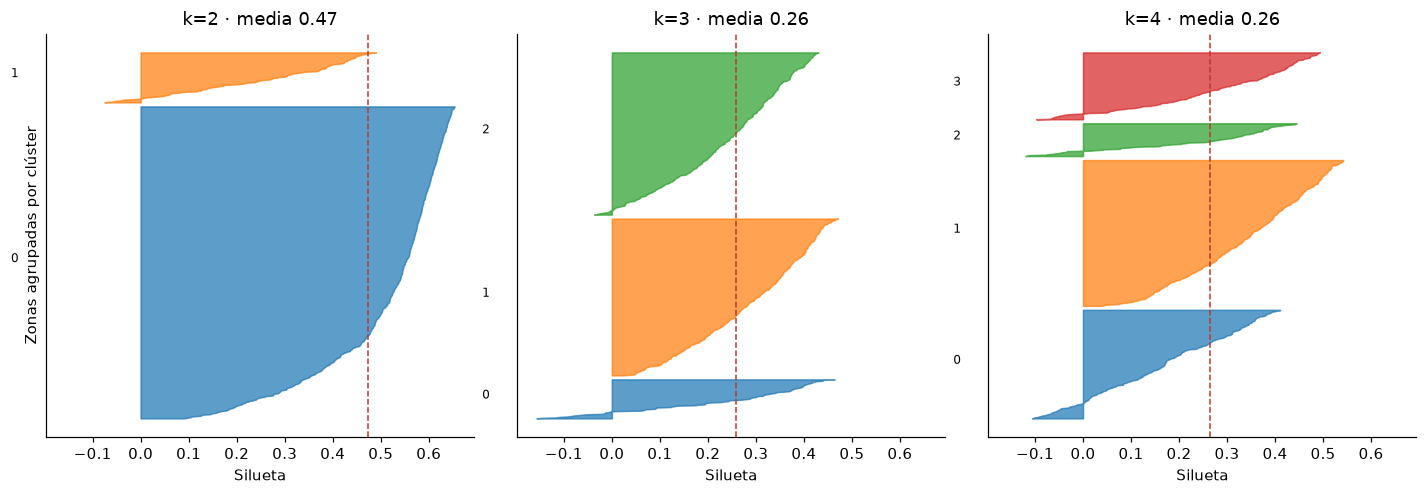

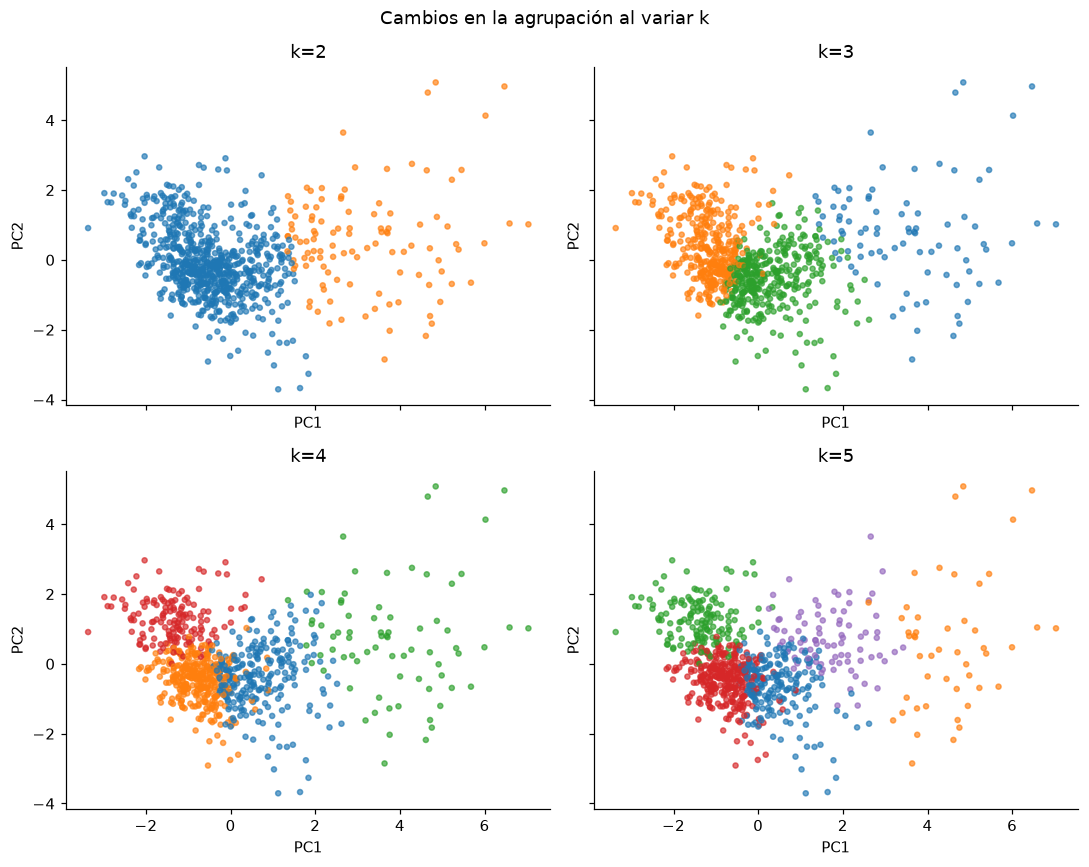

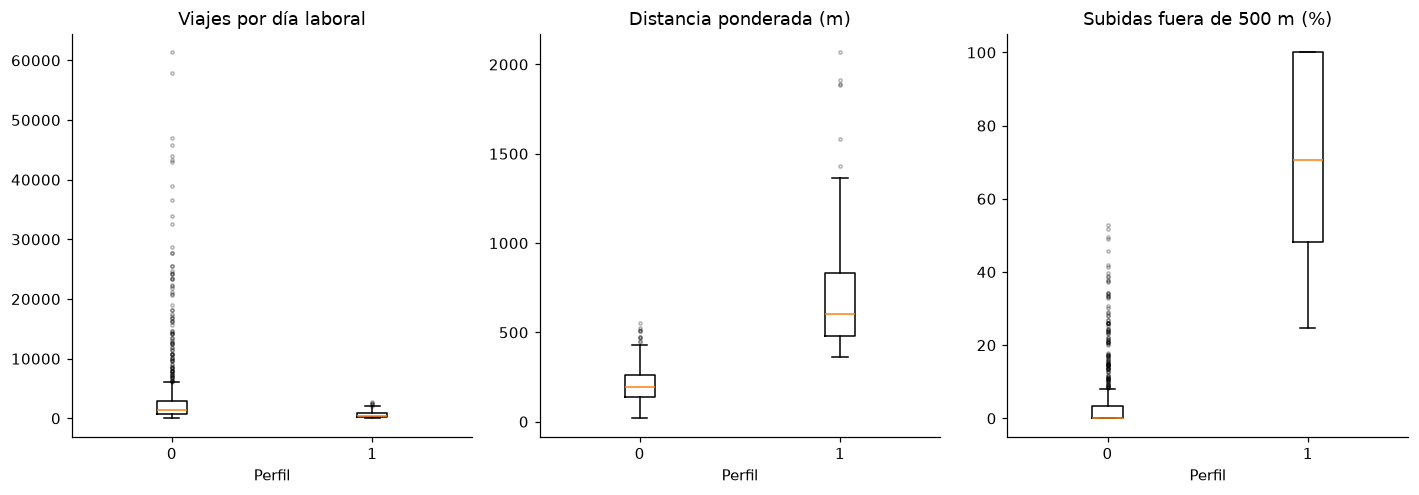

In [21]:
fig, axes = plt.subplots(1,3,figsize=(13,4.6), sharex=True)
for ax, k in zip(axes, [2,3,4]):
    labels = etiquetas[k]
    coef = silhouette_samples(estandarizadas, labels)
    inicio = 0
    for grupo in range(k):
        valores = np.sort(coef[labels == grupo])
        fin = inicio + len(valores)
        ax.fill_betweenx(np.arange(inicio, fin), 0, valores, color=plt.cm.tab10(grupo), alpha=.72)
        ax.text(-.27, (inicio+fin)/2, str(grupo), fontsize=8)
        inicio = fin + 8
    ax.axvline(coef.mean(), color='#ba392d', ls='--', lw=1)
    ax.set(title=f'k={k} · media {coef.mean():.2f}', xlabel='Silueta', yticks=[])
axes[0].set_ylabel('Zonas agrupadas por clúster')
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2,2,figsize=(10,8),sharex=True,sharey=True)
for ax, k in zip(axes.flat, [2,3,4,5]):
    ax.scatter(*coordenadas_pca.T, c=etiquetas[k], s=11, alpha=.65, cmap='tab10', vmin=0, vmax=9)
    ax.set(title=f'k={k}', xlabel='PC1', ylabel='PC2')
fig.suptitle('Cambios en la agrupación al variar k')
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1,3,figsize=(13,4.6))
agrupadas = list(zonas.loc[con_datos].groupby('cluster'))
for ax, variable, titulo in zip(axes, ['viajes_laborales_dia','distancia_media_ponderada_m','pct_subidas_sin_500m'],
                               ['Viajes por día laboral','Distancia ponderada (m)','Subidas fuera de 500 m (%)']):
    ax.boxplot([sub[variable] for _,sub in agrupadas], tick_labels=[str(g) for g,_ in agrupadas],
               flierprops={'markersize':2,'alpha':.3})
    ax.set(title=titulo, xlabel='Perfil')
fig.tight_layout()
plt.show()

## 5. Regresión de subidas por paradero

Se comparan media de entrenamiento, Ridge y Random Forest sobre las mismas comunas retenidas, con una semilla fija. Los modelos reciben ubicación, número de rutas de bus programadas en la parada, densidad de paraderos vecinos y variables de acceso a recarga. La comparación adicional de Ridge sin atributos de recarga mide su aporte predictivo incremental con la misma partición. El GTFS es una fotografía próxima a los datos, por lo que el análisis es transversal. Las métricas están en subidas/día y las estimaciones se truncan en cero.

MAE y RMSE se presentan en subidas/día. La Clase 7 (p. 24) los presenta junto con MAPE para pronóstico. En esta regresión se agrega R² de prueba, que compara el error cuadrático del modelo con el de una predicción constante igual a la media observada del conjunto de prueba. Puede ser negativo. El Dummy reportado usa la media de entrenamiento, por lo que su R² de prueba puede quedar ligeramente por debajo de cero. El pronóstico horario se compara con MAE y RMSE contra la referencia estacional.

Comunas de prueba: CONCHALI, ESTACION CENTRAL, LA REINA, PROVIDENCIA, PUDAHUEL, QUINTA NORMAL, SAN BERNARDO, SAN RAMON


,Modelo,MAE,RMSE,R2,n_train,n_test
0,Ridge con recarga,175.77,406.69,0.17,9197,2732
1,Ridge sin recarga,179.76,422.91,0.10,9197,2732
2,Random Forest,180.55,444.05,0.01,9197,2732
3,Dummy (media),222.72,446.53,-0.00,9197,2732


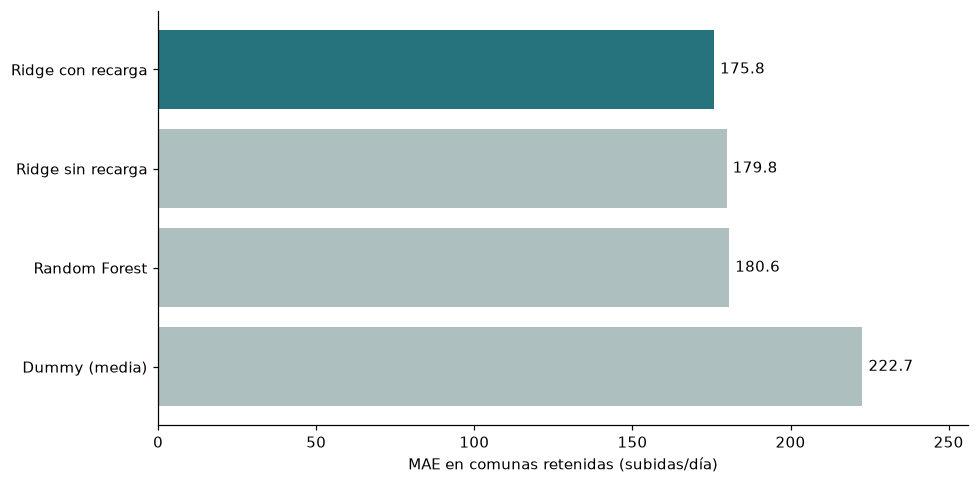

In [22]:
modelo_df = maestro.loc[maestro.COMUNA.ne('')].copy()
base_features = ['rutas_bus_gtfs', 'paraderos_en_500m', 'X_UTM', 'Y_UTM', 'dist_centro_km']
completas = base_features + ['distancia_min_bip_m', 'bip_en_300m', 'bip_en_500m']
y = modelo_df.SUBIDAS_LABORAL
grupos = modelo_df.COMUNA
train, test = next(GroupShuffleSplit(n_splits=1, test_size=.20, random_state=SEMILLA).split(modelo_df, y, grupos))
assert set(grupos.iloc[train]).isdisjoint(grupos.iloc[test])
ridge = Pipeline([('escala', StandardScaler()), ('regresion', Ridge(alpha=10))])
modelos = {
    'Dummy (media)': (DummyRegressor(), base_features),
    'Ridge sin recarga': (clone(ridge), base_features),
    'Ridge con recarga': (ridge, completas),
    'Random Forest': (RandomForestRegressor(n_estimators=150, max_depth=14, min_samples_leaf=2,
                                             random_state=SEMILLA, n_jobs=4), completas),
}
metricas_espaciales, pred_espaciales = [], {}
for nombre, (modelo, columnas) in modelos.items():
    x = modelo_df[columnas]
    pred = np.maximum(0, modelo.fit(x.iloc[train], y.iloc[train]).predict(x.iloc[test]))
    pred_espaciales[nombre] = pred
    metricas_espaciales.append({'Modelo': nombre, 'MAE': mean_absolute_error(y.iloc[test], pred),
                               'RMSE': np.sqrt(mean_squared_error(y.iloc[test], pred)),
                               'R2': r2_score(y.iloc[test], pred), 'n_train': len(train), 'n_test': len(test)})
metricas_espaciales = pd.DataFrame(metricas_espaciales).sort_values('MAE', ignore_index=True)
metricas_espaciales.to_csv(RESULTADOS / 'metricas_modelos_espaciales.csv', index=False)
print('Comunas de prueba:', ', '.join(sorted(grupos.iloc[test].unique())))
display(metricas_espaciales.round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
met = metricas_espaciales.sort_values('MAE', ascending=False)
bars = ax.barh(met.Modelo, met.MAE, color=['#aebfc0']*3+['#26737d'])
ax.bar_label(bars, fmt='%.1f', padding=4)
ax.set(xlabel='MAE en comunas retenidas (subidas/día)', xlim=(0, met.MAE.max()*1.15))
guardar_figura(fig, '04_modelos_espaciales.png')

### 5.1. Validación cruzada espacial y objetivo logarítmico

`GroupKFold` reevalúa los modelos dentro de las **comunas de entrenamiento**. Los hiperparámetros siguen fijos. Se recupera el Random Forest con `log1p(y)` de una entrega temprana como sensibilidad. Se usa `expm1` para evaluar en subidas/día y la misma lista de atributos que el Random Forest directo. La transformación cambia el objetivo de entrenamiento y puede atenuar las predicciones de paraderos de gran demanda. La prueba por comunas retenidas se mantiene como comparación principal.

In [23]:
rf_log = TransformedTargetRegressor(regressor=clone(modelos['Random Forest'][0]),
                                    func=np.log1p, inverse_func=np.expm1)
alternativa = {'Random Forest · log1p': (rf_log, completas)}
datos_cv, y_cv, grupos_cv = modelo_df.iloc[train], y.iloc[train], grupos.iloc[train]
cv = GroupKFold(n_splits=min(5, grupos_cv.nunique()))
resultados_cv = []
for pliegue, (sub_train, sub_val) in enumerate(cv.split(datos_cv, y_cv, grupos_cv), start=1):
    assert set(grupos_cv.iloc[sub_train]).isdisjoint(grupos_cv.iloc[sub_val])
    for nombre, (regresor, variables) in (modelos | alternativa).items():
        x_cv = datos_cv[variables]
        ajuste = clone(regresor).fit(x_cv.iloc[sub_train], y_cv.iloc[sub_train])
        pron = np.maximum(0, ajuste.predict(x_cv.iloc[sub_val]))
        resultados_cv.append({'Modelo': nombre, 'Pliegue': pliegue,
                              'MAE': mean_absolute_error(y_cv.iloc[sub_val], pron),
                              'RMSE': np.sqrt(mean_squared_error(y_cv.iloc[sub_val], pron)),
                              'R²': r2_score(y_cv.iloc[sub_val], pron)})
validacion_espacial = pd.DataFrame(resultados_cv)
display(validacion_espacial.groupby('Modelo').agg(
    MAE_medio=('MAE','mean'), MAE_desv=('MAE','std'), RMSE_medio=('RMSE','mean'), R2_medio=('R²','mean')
).sort_values('MAE_medio').round(2))

pred_log = np.maximum(0, rf_log.fit(modelo_df.iloc[train][completas], y.iloc[train]).predict(modelo_df.iloc[test][completas]))
metricas_log = {'Modelo':'Random Forest · log1p', 'MAE':mean_absolute_error(y.iloc[test], pred_log),
                'RMSE':np.sqrt(mean_squared_error(y.iloc[test], pred_log)), 'R2':r2_score(y.iloc[test], pred_log)}
metricas_sensibilidad = pd.concat([metricas_espaciales[['Modelo','MAE','RMSE','R2']],
                                  pd.DataFrame([metricas_log])], ignore_index=True).sort_values('MAE')
metricas_sensibilidad.to_csv(RESULTADOS / 'metricas_sensibilidad_espacial.csv', index=False)
display(metricas_sensibilidad.round(2))

,MAE_medio,MAE_desv,RMSE_medio,R2_medio
Modelo,,,,
Random Forest · log1p,170.07,32.84,594.47,0.07
Ridge sin recarga,200.72,38.35,574.27,0.14
Ridge con recarga,202.39,41.26,566.65,0.16
Random Forest,214.73,58.57,620.19,-0.05
Dummy (media),240.08,18.35,618.47,-0.01


,Modelo,MAE,RMSE,R2
4,Random Forest · log1p,141.01,417.76,0.12
0,Ridge con recarga,175.77,406.69,0.17
1,Ridge sin recarga,179.76,422.91,0.10
2,Random Forest,180.55,444.05,0.01
3,Dummy (media),222.72,446.53,-0.00


### 5.2. Predicciones, residuos e importancia predictiva

El gráfico observado–predicho usa una escala simétrica logarítmica para mostrar ceros y grandes flujos. Los residuos se calculan como predicción menos observación. La importancia por permutación mide cuánto aumenta el MAE del Random Forest al desordenar una variable en las comunas retenidas. Los atributos correlacionados pueden compensarse entre sí y la importancia describe el modelo, no el efecto de intervenir.

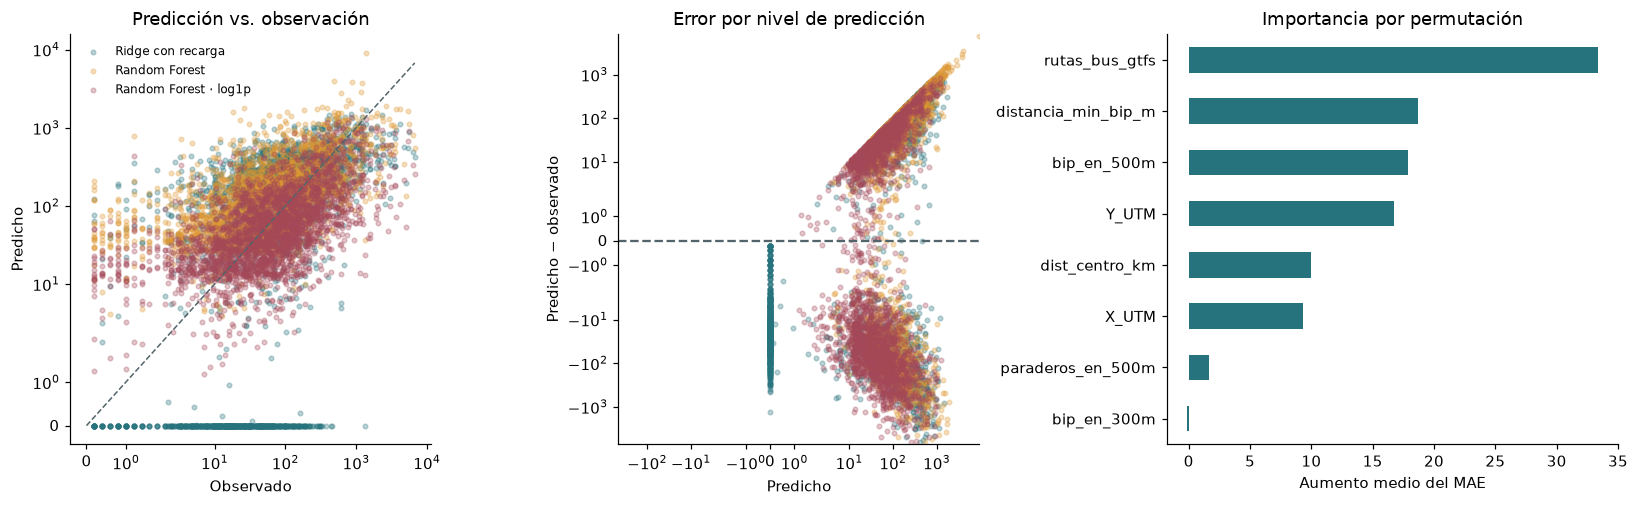

In [24]:
observado = y.iloc[test].to_numpy()
fig, axes = plt.subplots(1,3,figsize=(15,4.7),gridspec_kw={'width_ratios':[1,1,1.25]})
pred_diagnostico = {'Ridge con recarga':pred_espaciales['Ridge con recarga'],
                    'Random Forest':pred_espaciales['Random Forest'], 'Random Forest · log1p':pred_log}
for (nombre, valores), color in zip(pred_diagnostico.items(), ['#26737d','#e09832','#a44859']):
    axes[0].scatter(observado, valores, color=color, alpha=.3, s=9, label=nombre)
    axes[1].scatter(valores, valores-observado, color=color, alpha=.3, s=9)
axes[0].plot([0, observado.max()], [0, observado.max()], ls='--', color='#53646a', lw=1)
axes[0].set(title='Predicción vs. observación', xlabel='Observado', ylabel='Predicho', xscale='symlog', yscale='symlog')
axes[0].legend(frameon=False, fontsize=8)
axes[1].axhline(0, color='#53646a', ls='--')
axes[1].set(title='Error por nivel de predicción', xlabel='Predicho', ylabel='Predicho − observado', xscale='symlog', yscale='symlog')
permutaciones = permutation_importance(modelos['Random Forest'][0], modelo_df.iloc[test][completas], observado,
                                       scoring='neg_mean_absolute_error', n_repeats=5, random_state=SEMILLA)
pd.Series(permutaciones.importances_mean,index=completas).sort_values().plot.barh(ax=axes[2],color='#26737d')
axes[2].set(title='Importancia por permutación', xlabel='Aumento medio del MAE')
fig.tight_layout()
plt.show()

## 6. Pronóstico horario de viajes registrados

Para cada día de prueba se usan solo las horas anteriores. Se evalúan 24 horas de los días 15, 16 y 17 de abril. El baseline copia la hora correspondiente del día anterior. ARIMA(1,1,1) y SARIMA(1,0,0)(1,0,0,24) pronostican las mismas ventanas. El ciclo estacional es diario y la semana disponible permite una prueba exploratoria de horizonte corto. Se registra la convergencia y se promedian los errores por ventana.

,MAE,RMSE,ventanas,convergencias
Modelo,,,,
Ingenuo estacional (24 h),5847.1,9419.8,3,3
"SARIMA(1,0,0)(1,0,0,24)",7127.2,11571.2,3,3
"ARIMA(1,1,1)",109688.1,139899.8,3,3


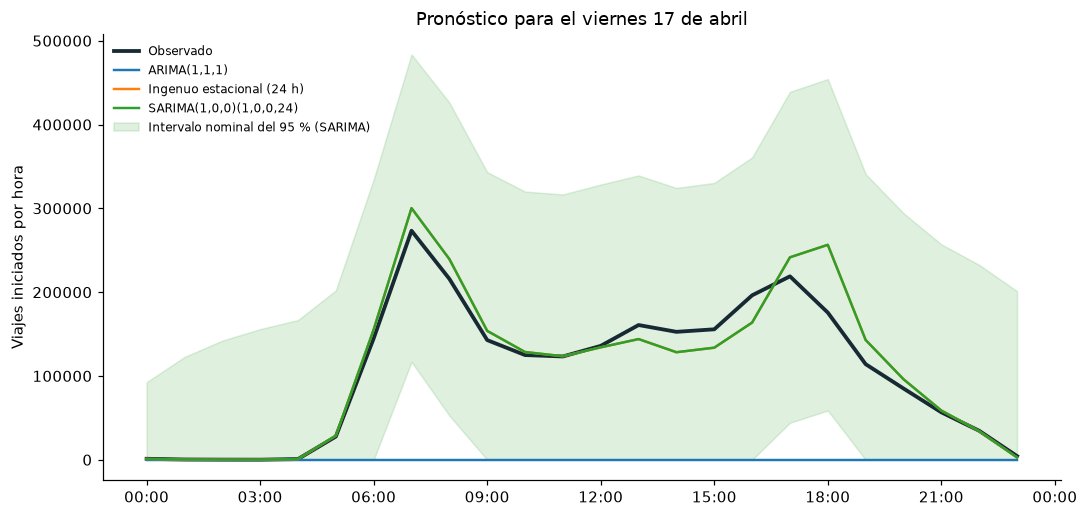

In [25]:
serie = serie_df.set_index('fecha_hora').viajes_totales.asfreq('h').astype(float)
registros, predicciones = [], []
for fecha in pd.date_range('2026-04-15', '2026-04-17', freq='D'):
    train_t = serie[serie.index < fecha]
    test_t = serie[(serie.index >= fecha) & (serie.index < fecha + pd.Timedelta(days=1))]
    assert len(test_t) == 24 and train_t.index.max() < test_t.index.min()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=UserWarning)
        with threadpool_limits(limits=1):
            arima = ARIMA(train_t, order=(1,1,1)).fit(method_kwargs={'maxiter':200})
            sarima = SARIMAX(train_t, order=(1,0,0), seasonal_order=(1,0,0,24),
                             enforce_stationarity=False).fit(disp=False, maxiter=200)
    # Adaptado de la Actividad de ARIMA, sección de pronóstico SARIMA.
    forecast_sarima = sarima.get_forecast(steps=len(test_t))
    pred_sarima = forecast_sarima.predicted_mean
    intervalo_sarima = forecast_sarima.conf_int()
    pronosticos = {'Ingenuo estacional (24 h)': (train_t.tail(24).to_numpy(), True),
                   'ARIMA(1,1,1)': (arima.forecast(24), arima.mle_retvals['converged']),
                   'SARIMA(1,0,0)(1,0,0,24)': (pred_sarima, sarima.mle_retvals['converged'])}
    for nombre, (pred, convergio) in pronosticos.items():
        pred = np.maximum(0, np.asarray(pred))
        registros.append({'Fecha_test': fecha.date().isoformat(), 'Modelo': nombre,
                          'MAE': mean_absolute_error(test_t, pred), 'RMSE': np.sqrt(mean_squared_error(test_t, pred)),
                          'convergio': bool(convergio)})
        predicciones.append(pd.DataFrame({'fecha_hora': test_t.index, 'Modelo': nombre, 'real': test_t.to_numpy(), 'pred': pred}))
metricas_temporales = pd.DataFrame(registros)
pred_temporales = pd.concat(predicciones, ignore_index=True)
metricas_temporales.to_csv(RESULTADOS / 'metricas_modelos_temporales.csv', index=False)
promedios_t = metricas_temporales.groupby('Modelo').agg(MAE=('MAE','mean'), RMSE=('RMSE','mean'),
                                                        ventanas=('Fecha_test','nunique'), convergencias=('convergio','sum')).sort_values('MAE')
display(promedios_t.round(1))
fig, ax = plt.subplots(figsize=(10, 4.8))
ultima = pred_temporales.loc[pred_temporales.fecha_hora.dt.normalize().eq(fecha)]
ax.plot(ultima.fecha_hora.unique(), ultima.real.iloc[:24], color='#172a33', lw=2.5, label='Observado')
for nombre, grupo in ultima.groupby('Modelo'):
    linea, = ax.plot(grupo.fecha_hora, grupo.pred, lw=1.6, label=nombre)
    if nombre.startswith('SARIMA'):
        ax.fill_between(grupo.fecha_hora, intervalo_sarima.iloc[:, 0].clip(lower=0),
                        intervalo_sarima.iloc[:, 1].clip(lower=0),
                        color=linea.get_color(), alpha=.15, label='Intervalo nominal del 95 % (SARIMA)')
ax.set(title='Pronóstico para el viernes 17 de abril', ylabel='Viajes iniciados por hora')
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%H:%M'))
ax.legend(frameon=False, fontsize=8)
guardar_figura(fig, '06_pronostico_temporal.png')

**Errores por fecha.** Se mantienen visibles las tres ventanas y el indicador de convergencia de cada ajuste. Tres días retenidos dentro de una sola semana ofrecen evidencia exploratoria de pronóstico horario.

Se adaptó el uso de `get_forecast` y `conf_int` de la actividad de ARIMA para el último corte de SARIMA. La banda corresponde al intervalo nominal del 95 % condicionado al modelo y sus supuestos, con límites truncados en cero para la gráfica. Tres ventanas son insuficientes para demostrar calibración.

In [26]:
display(metricas_temporales.sort_values(['Fecha_test','MAE']).round(1))

,Fecha_test,Modelo,MAE,RMSE,convergio
0,2026-04-15,Ingenuo estacional (24 h),1987.3,2644.2,True
2,2026-04-15,"SARIMA(1,0,0)(1,0,0,24)",4809.2,7483.7,True
1,2026-04-15,"ARIMA(1,1,1)",111808.5,143827.6,True
3,2026-04-16,Ingenuo estacional (24 h),2128.2,3292.9,True
5,2026-04-16,"SARIMA(1,0,0)(1,0,0,24)",3144.8,4900.5,True
4,2026-04-16,"ARIMA(1,1,1)",111183.8,142328.1,True
6,2026-04-17,Ingenuo estacional (24 h),13425.7,22322.4,True
8,2026-04-17,"SARIMA(1,0,0)(1,0,0,24)",13427.6,22329.3,True
7,2026-04-17,"ARIMA(1,1,1)",106072.0,133543.6,True


## 7. Emparejamiento observacional

Como ejercicio vinculado con causalidad, se compara la media de subidas entre paraderos con y sin recarga a 300 m. Se ajusta el puntaje de propensión por posición y distancia al centro y se empareja 1:1 con reemplazo en el soporte común. El balance reporta diferencias de medias estandarizadas (SMD) para las tres covariables. Los resultados describen una asociación ajustada por esas covariables. Comercio, conectividad y frecuencia siguen siendo posibles confundentes y no se mide el efecto de instalar un punto de recarga.

In [27]:
CONF=['X_UTM','Y_UTM','dist_centro_km']
df_obs=maestro.copy()
df_obs['T']=(df_obs.distancia_min_bip_m<=RADIO_CERCANO_M).astype(int)
reporte_psm=None; balance_psm=pd.DataFrame()
if df_obs['T'].nunique()<2:
    print('PSM omitido: solo existe un grupo de accesibilidad.')
else:
    ps=Pipeline([('escala',StandardScaler()),('logistica',LogisticRegression(max_iter=1000,random_state=SEMILLA))])
    ps.fit(df_obs[CONF],df_obs['T'])
    df_obs['propension']=np.clip(ps.predict_proba(df_obs[CONF])[:,1],1e-6,1-1e-6)
    tratados=df_obs[df_obs['T']==1].copy(); controles=df_obs[df_obs['T']==0].copy()
    izq=max(tratados.propension.min(),controles.propension.min())
    der=min(tratados.propension.max(),controles.propension.max())
    tratados=tratados[tratados.propension.between(izq,der)]
    controles=controles[controles.propension.between(izq,der)]
    if min(len(tratados),len(controles))<15:
        print('PSM omitido: menos de 15 observaciones por grupo tras soporte común.')
    else:
        vecinos=NearestNeighbors(n_neighbors=1).fit(controles[['propension']])
        _,idx=vecinos.kneighbors(tratados[['propension']])
        control_match=controles.iloc[idx.ravel()].copy()
        def smd(a,b):
            var=(np.var(a,ddof=1)+np.var(b,ddof=1))/2
            return float((np.mean(a)-np.mean(b))/np.sqrt(var)) if var>0 else np.nan
        for v in CONF:
            balance_psm=pd.concat([balance_psm,pd.DataFrame([{'Covariable':v,
                'SMD_antes':smd(df_obs.loc[df_obs['T']==1,v],df_obs.loc[df_obs['T']==0,v]),
                'SMD_despues':smd(tratados[v],control_match[v])}])],ignore_index=True)
        diferencia=float((tratados.SUBIDAS_LABORAL.to_numpy()-control_match.SUBIDAS_LABORAL.to_numpy()).mean())
        reporte_psm={'n_tratados_soporte':int(len(tratados)),'n_controles_soporte':int(len(controles)),
            'controles_distintos_emparejados':int(control_match.index.nunique()),
            'diferencia_media_ajustada_descriptiva':diferencia,
            'max_smd_post':float(balance_psm.SMD_despues.abs().max())}
        print('Diferencia media ajustada de subidas por día:', round(diferencia, 2))
        display(balance_psm.round(3));print(reporte_psm)
        balance_psm.to_csv(RESULTADOS/'balance_emparejamiento_psm.csv',index=False)

Diferencia media ajustada de subidas por día: 173.72


,Covariable,SMD_antes,SMD_despues
0,X_UTM,-0.070,-0.035
1,Y_UTM,0.188,0.009
2,dist_centro_km,-0.432,0.002


{'n_tratados_soporte': 6990, 'n_controles_soporte': 4874, 'controles_distintos_emparejados': 2945, 'diferencia_media_ajustada_descriptiva': 173.72163090128754, 'max_smd_post': 0.035333785261730866}


### 7.1. Soporte, balance y diferencias observacionales

El histograma de propensión muestra el soporte común usado en el emparejamiento. El gráfico de balance compara diferencias estandarizadas absolutas. La guía en 0,1 es orientativa. La comparación de medias bruta y ajustada conserva el carácter asociativo. El emparejamiento reutiliza controles y ajusta solo las covariables geográficas incluidas.

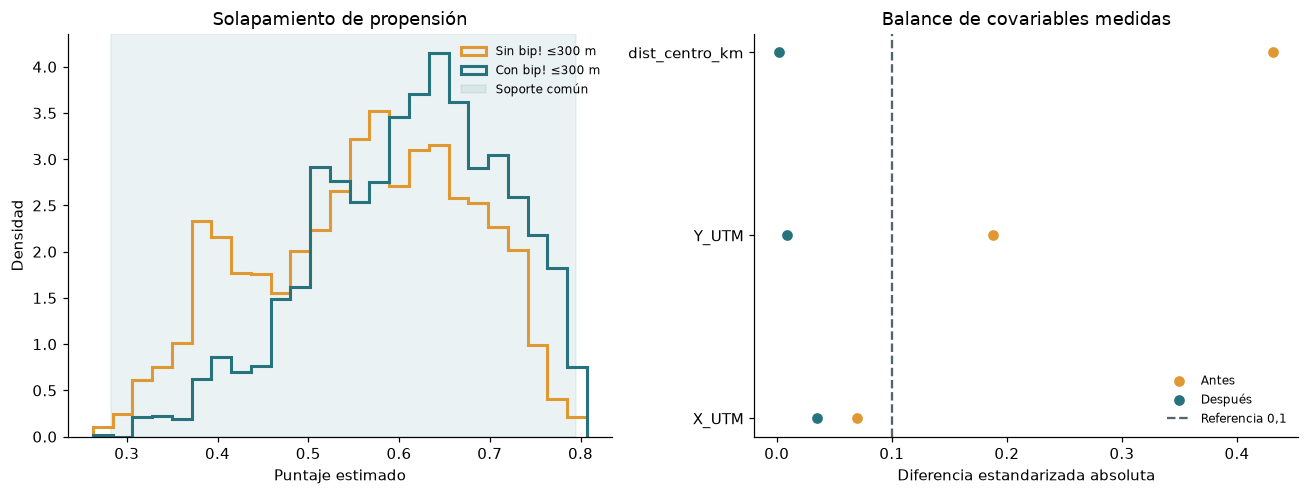

Diferencia no ajustada: 181,7 subidas/día. Diferencia ajustada descriptiva: 173,7 subidas/día.


In [28]:
if reporte_psm is not None:
    fig, axes = plt.subplots(1,2,figsize=(12,4.6))
    bins_psm = np.linspace(df_obs.propension.min(),df_obs.propension.max(),26)
    for estado, color, nombre in [(0,'#e09832','Sin bip! ≤300 m'), (1,'#26737d','Con bip! ≤300 m')]:
        valores = df_obs.loc[df_obs['T'].eq(estado), 'propension']
        axes[0].hist(valores,bins=bins_psm,density=True,histtype='step',lw=2,color=color,label=nombre)
    axes[0].axvspan(izq, der, color='#26737d', alpha=.09, label='Soporte común')
    axes[0].set(title='Solapamiento de propensión', xlabel='Puntaje estimado', ylabel='Densidad')
    axes[0].legend(frameon=False, fontsize=8)
    axes[1].scatter(balance_psm.SMD_antes.abs(),balance_psm.Covariable,color='#e09832',label='Antes')
    axes[1].scatter(balance_psm.SMD_despues.abs(),balance_psm.Covariable,color='#26737d',label='Después')
    axes[1].axvline(.1,ls='--',color='#53646a',label='Referencia 0,1')
    axes[1].set(title='Balance de covariables medidas', xlabel='Diferencia estandarizada absoluta')
    axes[1].legend(frameon=False, fontsize=8)
    fig.tight_layout()
    plt.show()
    bruta = df_obs.groupby('T').SUBIDAS_LABORAL.mean().diff().iloc[-1]
    print(f'Diferencia no ajustada: {numero(bruta,1)} subidas/día. '
          f'Diferencia ajustada descriptiva: {numero(diferencia,1)} subidas/día.')

## 8. Ranking y simulación de cobertura

Se filtran los paraderos de prioridad crítica sin recarga a 500 m. El ranking del avance ordena `subidas × distancia en km` hasta 20 sitios, con separación mínima de 200 m. La simulación compara ese orden con una selección voraz del punto que ofrece acceso a más subidas desatendidas entre los sitios candidatos. Cada paradero se contabiliza una sola vez, incluso con radios de nuevos sitios superpuestos. El universo incluye los paraderos BUS enlazados con DTPM y sin recarga a 500 m. Los valores describen subidas preexistentes que quedarían al alcance en el escenario geométrico.

**Cómo funciona `simular_cobertura`.** Indexa los paraderos sin cobertura inicial y precomputa cuáles quedarían al alcance de cada sitio candidato. En cada paso suma las subidas de los paraderos nuevos cubiertos y aplica la separación entre sitios. La ganancia marginal es una heurística local. Si la separación agota los candidatos, la comparación del mapa y la síntesis usan el último presupuesto alcanzado por ambas estrategias. Las curvas conservan todas las selecciones disponibles.

In [29]:
def simular_cobertura(maestro, candidatos, ranking, radio, limite, separacion):
    """Compara el ranking original y una selección por cobertura marginal de subidas."""
    sin_cobertura = maestro.loc[maestro[f"bip_en_{radio}m"].eq(0)]
    xy_objetivo = sin_cobertura[["X_UTM", "Y_UTM"]].to_numpy()
    xy_candidatos = candidatos[["X_UTM", "Y_UTM"]].to_numpy()
    pesos = sin_cobertura.SUBIDAS_LABORAL.to_numpy()
    vecinos = [np.asarray(i, dtype=int) for i in cKDTree(xy_objetivo).query_ball_point(xy_candidatos, radio)]
    cercanos = cKDTree(xy_candidatos).query_ball_point(xy_candidatos, separacion)
    posiciones = {codigo: pos for pos, codigo in enumerate(candidatos.PARADA)}
    por_indice = [posiciones[codigo] for codigo in ranking.PARADA]
    salidas = []
    for metodo in ("Índice del avance", "Cobertura marginal"):
        cubiertos = np.zeros(len(pesos), dtype=bool)
        disponibles = np.ones(len(vecinos), dtype=bool)
        for paso in range(min(limite, len(por_indice))):
            if metodo == "Índice del avance":
                elegido = por_indice[paso]
            else:
                ganancias = np.full(len(vecinos), -1.0)
                for pos in np.flatnonzero(disponibles):
                    vec = vecinos[pos]
                    ganancias[pos] = pesos[vec[~cubiertos[vec]]].sum()
                elegido = int(np.argmax(ganancias))
                if ganancias[elegido] < 0:
                    break
                disponibles[elegido] = False
                for pos in cercanos[elegido]:
                    if np.linalg.norm(xy_candidatos[pos] - xy_candidatos[elegido]) < separacion:
                        disponibles[pos] = False
            vec = vecinos[elegido]
            ganancia = float(pesos[vec[~cubiertos[vec]]].sum())
            cubiertos[vec] = True
            salidas.append({"metodo": metodo, "sitios": paso + 1, "paradero": candidatos.PARADA.iloc[elegido],
                            "subidas_adicionales_con_cobertura": ganancia,
                            "subidas_acumuladas_con_cobertura": float(pesos[cubiertos].sum()),
                            "paraderos_cubiertos": int(cubiertos.sum())})
    return pd.DataFrame(salidas)

Sitios seleccionados por estrategia: {'Cobertura marginal': 20, 'Índice del avance': 20}
Presupuesto comparable: 20 sitios por estrategia.


,RANK,CODIGO_PUBLICO,COMUNA,zona_777,SUBIDAS_LABORAL,distancia_min_bip_m,REFERENCIA
0,1,PC907,LO BARNECHEA,639,695.0,2040.6,Parada / Rotonda Pie Andino
1,2,PC744,VITACURA,192,1316.0,910.5,Avenida Santa María / esq. Carolina Rabat
2,3,PB1005,QUILICURA,557,463.0,2484.0,San Ignacio / esq. Galvarino
3,4,PI356,CERRILLOS,156,1528.2,671.3,Parada / Mall Plaza Oeste
4,5,PC975,LAS CONDES,228,1132.4,886.3,Parada / Portal La Reina
5,6,PC1098,LO BARNECHEA,639,297.0,3336.4,Paseo Los Bravos / esq. Cam. Juan Pablo II
6,7,PC623,LAS CONDES,541,1847.8,535.3,General Blanche / esq. Sn. C. de Apoquindo
7,8,PC908,LO BARNECHEA,639,555.8,1603.4,Camino Los Trapenses / esq. Pedro Lira Urquieta
8,9,PB1004,QUILICURA,557,380.8,2105.9,San Ignacio / esq. Lincoyán
9,10,PC115,LAS CONDES,211,1305.4,612.1,Avenida Las Condes / esq. Psje. Las Condes


,metodo,sitios,paradero,subidas_adicionales_con_cobertura,subidas_acumuladas_con_cobertura,paraderos_cubiertos
4,Índice del avance,5,L-17-36-15-OP,1668.6,8507.6,29
9,Índice del avance,10,T-17-136-OP-5,1704.8,12541.6,41
19,Índice del avance,20,T-6-7-PO-40,1055.6,23747.6,100
24,Cobertura marginal,5,T-17-136-OP-30,2419.4,13853.4,65
29,Cobertura marginal,10,T-21-205-SN-55,2116.8,24877.2,150
39,Cobertura marginal,20,T-12-55-SN-40,1589.6,42784.0,244


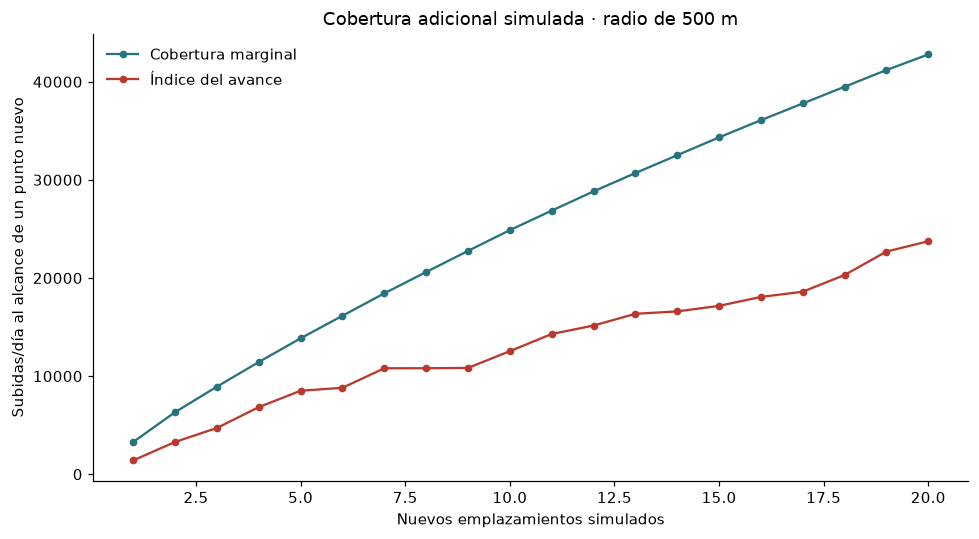

In [30]:
candidatos = maestro.loc[maestro.prioridad_territorial.eq('Prioridad crítica') &
                         maestro.bip_en_500m.eq(0)].sort_values(
                             ['indice_estres','SUBIDAS_LABORAL','PARADA'], ascending=[False,False,True])
indices, ubicaciones = [], []
for fila in candidatos.itertuples():
    punto = np.array([fila.X_UTM, fila.Y_UTM])
    if all(np.linalg.norm(punto-previo) >= SEPARACION_CANDIDATOS_M for previo in ubicaciones):
        indices.append(fila.Index)
        ubicaciones.append(punto)
    if len(indices) == TOP_N:
        break
ranking = candidatos.loc[indices].reset_index(drop=True)
ranking.insert(0, 'RANK', np.arange(1, len(ranking)+1))
ranking.to_csv(RESULTADOS / 'ranking_candidatos_bip.csv', index=False)
cobertura = simular_cobertura(maestro, candidatos, ranking, 500, TOP_N, SEPARACION_CANDIDATOS_M)
cobertura.to_csv(RESULTADOS / 'comparacion_cobertura_500m.csv', index=False)
presupuestos = cobertura.groupby('metodo').sitios.max()
assert len(presupuestos) == 2, 'Se necesita al menos un sitio por estrategia para la comparación.'
presupuesto_comun = int(presupuestos.min())
cobertura_comparable = cobertura.loc[cobertura.sitios.le(presupuesto_comun)]
print('Sitios seleccionados por estrategia:', presupuestos.to_dict())
print(f'Presupuesto comparable: {presupuesto_comun} sitios por estrategia.')
display(ranking[['RANK','CODIGO_PUBLICO','COMUNA','zona_777','SUBIDAS_LABORAL','distancia_min_bip_m','REFERENCIA']].head(10).round(1))
display(cobertura_comparable.loc[cobertura_comparable.sitios.isin([5,10,presupuesto_comun])].round(1))
fig, ax = plt.subplots(figsize=(9, 5))
for (nombre, tabla), color in zip(cobertura.groupby('metodo'), ['#26737d','#ba392d']):
    ax.plot(tabla.sitios, tabla.subidas_acumuladas_con_cobertura, marker='o', ms=4, color=color, label=nombre)
ax.legend(frameon=False)
ax.set(xlabel='Nuevos emplazamientos simulados', ylabel='Subidas/día al alcance de un punto nuevo',
       title='Cobertura adicional simulada · radio de 500 m')
guardar_figura(fig, '08_ranking_candidatos.png')

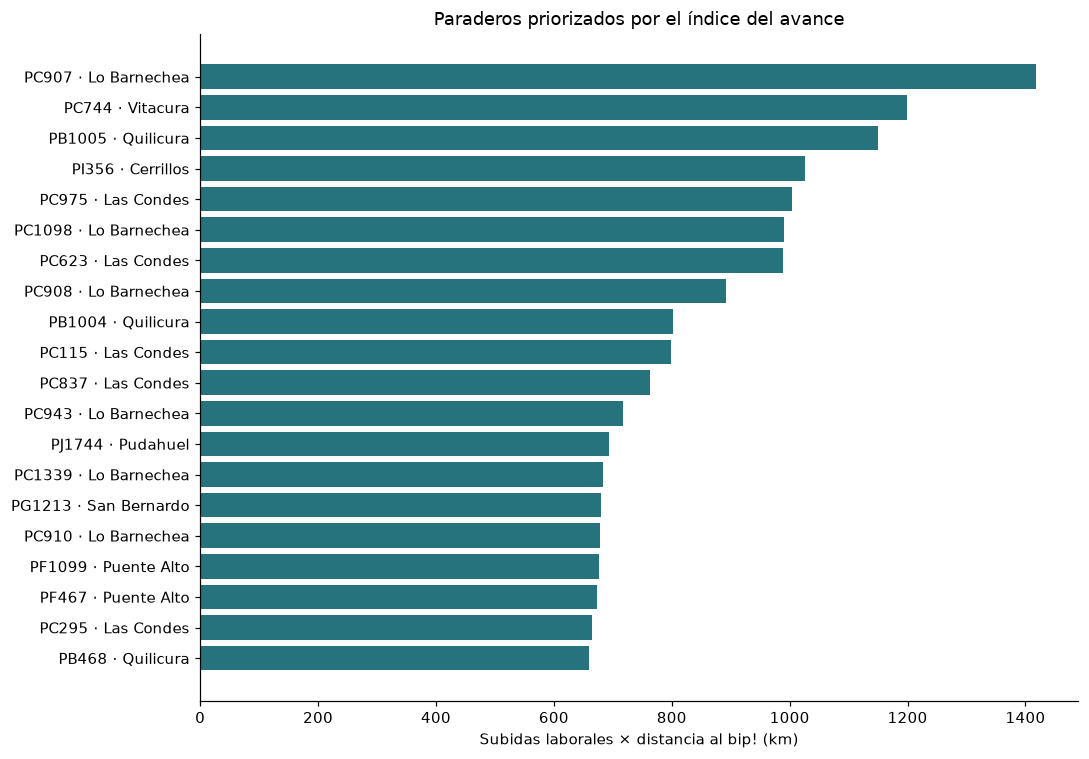

In [31]:
fig, ax = plt.subplots(figsize=(10, 7))
ranking_grafico = ranking.sort_values('RANK', ascending=False)
etiquetas_sitios = ranking_grafico.CODIGO_PUBLICO + ' · ' + ranking_grafico.COMUNA.str.title()
ax.barh(etiquetas_sitios, ranking_grafico.indice_estres, color='#26737d')
ax.set(title='Paraderos priorizados por el índice del avance', xlabel='Subidas laborales × distancia al bip! (km)')
fig.tight_layout()
plt.show()

## 9. Mapa para el live demo y auditoría

Abra `resultados_integral/Live_Demo_BIP.html`. El mapa permite explorar los cuadrantes, alternar la oferta y los candidatos, ampliar una zona y comparar ambas estrategias. Los polígonos corresponden a la cartografía local de DTPM. El mapa usa norte arriba y distancias UTM. La vista inicial resalta las zonas críticas y los candidatos por índice.

Active Bus, Metro o Tren para ver cada modo. La capa Bus incluye los paraderos del análisis. Metro aparece en la capa de transporte y en la de recarga. La capa Tren muestra estaciones de referencia del GTFS. El ranking selecciona paraderos de bus, incluso cuando llevan el nombre de una estación o de un intermodal.

**Cómo funciona `exportar_mapa`.** Reduce las geometrías a vértices en metros y serializa únicamente indicadores agregados, puntos de recarga y sitios seleccionados. Inserta el JSON en una plantilla HTML y admite abrir el archivo local sin un servicio de mapas. El código de la plantilla se conserva en una celda porque es parte de la demo. La visualización cartográfica se guarda junto con las demás salidas de este notebook.

In [32]:
def exportar_mapa(ruta, plantilla_html, geometrias, zonas, df_bip, candidatos, cobertura, transporte):
    import shapely

    def registros(tabla, columnas):
        return json.loads(tabla[columnas].round(2).to_json(orient="records", force_ascii=False))

    zonas_mapa = registros(zonas, ["zona_777", "comuna_cartografica", "cuadrante", "perfil",
                                  "puntos_bip_internos", "viajes_laborales_dia", "subidas_bus_dia",
                                  "pct_subidas_sin_300m", "pct_subidas_sin_500m",
                                  "distancia_media_ponderada_m"])
    for zona in zonas_mapa:
        geom = geometrias[zona["zona_777"]].simplify(5, preserve_topology=True)
        zona["poligonos"] = [[[[round(x), round(y)] for x, y in anillo.coords]
                              for anillo in (parte.exterior, *parte.interiors)]
                             for parte in shapely.get_parts(geom)]
    datos = {
        "zonas": zonas_mapa,
        "bip": registros(df_bip, ["ESTE", "NORTE", "ENTIDAD", "NOMBRE_FANTASIA"]),
        "transporte": registros(transporte, ["modo", "nombre", "x", "y"]),
        "sitios": registros(candidatos.loc[candidatos.PARADA.isin(cobertura.paradero)],
                            ["PARADA", "CODIGO_PUBLICO", "COMUNA", "REFERENCIA", "X_UTM", "Y_UTM",
                             "SUBIDAS_LABORAL", "distancia_min_bip_m", "zona_777"]),
        "cobertura": registros(cobertura, ["metodo", "sitios", "paradero", "subidas_acumuladas_con_cobertura"]),
    }
    contenido = json.dumps(datos, ensure_ascii=False, separators=(",", ":")).replace("<", "\\u003c")
    ruta.write_text(plantilla_html.replace("__DATOS_PROYECTO__", contenido), encoding="utf-8")

In [33]:
PLANTILLA_MAPA = '<!doctype html>\n<html lang="es">\n<head>\n<meta charset="utf-8">\n<meta name="viewport" content="width=device-width, initial-scale=1">\n<title>Desiertos de recarga bip! · Santiago</title>\n<style>\n:root{color-scheme:light;--ink:#172e34;--muted:#4f656a;--bg:#f1f5f2;--line:#d7e3de;--red:#a92c23;--blue:#26737d}\n*{box-sizing:border-box}body{margin:0;background:var(--bg);color:var(--ink);font:15px/1.45 system-ui,sans-serif}\nheader{background:#132f33;color:#fff;padding:24px clamp(16px,4vw,64px) 22px;display:flex;gap:18px;align-items:end;justify-content:space-between;flex-wrap:wrap}h1{font-size:clamp(27px,4vw,43px);line-height:1.07;margin:0 0 7px;letter-spacing:-.045em}header p{margin:0;color:#bcdbd7}header strong{font-size:14px;background:#29494a;padding:8px 11px;border-radius:6px}\nmain{display:grid;grid-template-columns:minmax(0,1fr) minmax(265px,345px);gap:17px;padding:17px clamp(12px,3vw,42px)}.panel,.map{background:white;border:1px solid var(--line);border-radius:12px}.map{position:relative;min-height:610px;overflow:hidden;background:#edf2ee}.map canvas{width:100%;height:100%;position:absolute;inset:0;touch-action:none;cursor:grab}.map canvas:active{cursor:grabbing}\n.tools,.zoom,.scale{position:absolute;z-index:1}.tools{top:12px;left:12px;right:12px;display:flex;flex-wrap:wrap;gap:6px;pointer-events:none}.tools label{pointer-events:auto;font-size:13px;background:#fff;padding:5px 8px;border:1px solid var(--line);border-radius:5px;display:flex;align-items:center;gap:5px}.zoom{bottom:13px;right:13px;display:flex;gap:4px}.zoom button{height:36px;min-width:34px}.scale{bottom:15px;left:16px;font-size:12px;border-bottom:2px solid #28464a;font-weight:700}.north{position:absolute;top:61px;right:18px;text-align:center;line-height:1;font-size:14px;font-weight:700;pointer-events:none}\nbutton,select,input{font:inherit}button,select{color:var(--ink);border:1px solid #a5b9b2;background:#fff;border-radius:6px}button{cursor:pointer;padding:5px 9px}button:hover,button[aria-current="true"]{background:#e4efea}button:focus-visible,select:focus-visible,canvas:focus-visible,input:focus-visible{outline:3px solid #26737d;outline-offset:2px}input[type=checkbox]{accent-color:var(--blue)}\naside{display:flex;flex-direction:column;gap:12px;min-width:0}.panel{padding:13px 15px}.panel h2{font-size:17px;margin:0 0 6px}.panel p{margin:4px 0;color:var(--muted);font-size:13px}.panel select{width:100%;margin:4px 0 7px;padding:6px 8px}.legend{display:grid;gap:5px;margin-top:5px;font-size:13px}.swatch{display:inline-block;width:12px;height:12px;border-radius:3px;margin-right:8px;vertical-align:-1px}.dot{border-radius:50%}\n.ranking{display:grid;gap:4px;max-height:144px;overflow:auto;padding:2px}.ranking button{text-align:left;font-size:13px;display:grid;grid-template-columns:5ch 1fr;gap:6px}.ranking span{color:var(--muted)}.detail{min-height:120px}.detail dl{margin:4px 0 0;display:grid;grid-template-columns:1fr auto;gap:4px 9px;font-size:13px}.detail dd{margin:0;text-align:right;font-weight:650}.mark{color:var(--red);font-weight:700}.outcome{font-size:18px;font-weight:750}.note{font-size:12px;color:var(--muted);margin:0;padding:0 clamp(12px,3vw,42px) 16px}\n@media(max-width:800px){main{grid-template-columns:1fr}.map{min-height:480px}aside{display:grid;grid-template-columns:repeat(auto-fit,minmax(230px,1fr))}}\n@media(max-width:430px){.map{min-height:410px}.tools label{font-size:11px;padding:4px}.north{top:83px}}\n</style>\n</head>\n<body>\n<header><div><h1>Desiertos de recarga bip!</h1><p>Santiago · Acceso a recarga por Zona 777</p></div><strong id="cifra"></strong></header>\n<main>\n  <section class="map" aria-label="Mapa de Santiago">\n    <canvas id="mapa" tabindex="0" aria-label="Mapa de zonas y candidatos. Use las flechas para desplazar, + y − para ampliar o reducir."></canvas>\n    <div class="tools"><label><input id="zonas" type="checkbox" checked> Zonas de transporte</label><label><input id="bip" type="checkbox"> Puntos bip!</label><label><input id="sitios" type="checkbox" checked> Candidatos en paraderos</label><label><input id="radio" type="checkbox"> Radio del sitio activo</label><label><input id="bus" type="checkbox"> Bus</label><label><input id="metro" type="checkbox"> Metro</label><label><input id="tren" type="checkbox"> Tren</label></div>\n    <div class="north" aria-label="Norte">N<br>▲</div><div class="scale" id="escala"></div>\n    <div class="zoom"><button id="menos" aria-label="Reducir">−</button><button id="mas" aria-label="Ampliar">+</button><button id="inicio">Vista completa</button></div>\n  </section>\n  <aside>\n    <section class="panel"><h2>Cuadrantes de prioridad</h2><label for="filtro">Resaltar zonas</label><select id="filtro"><option value="">Todas</option><option>Prioridad crítica</option><option>Prioridad de accesibilidad</option><option>Alta demanda con recarga próxima</option><option>Menor prioridad</option><option>Sin datos comparables</option></select><div class="legend" id="leyenda"></div></section>\n    <section class="panel detail" aria-live="polite"><h2 id="detalle-titulo">Detalle del mapa</h2><div id="detalle"><p>Seleccione una zona o un sitio para ver sus indicadores.</p></div></section>\n    <section class="panel"><h2>Paraderos candidatos</h2><p>Los candidatos son paraderos de bus. Las estaciones de Metro cuentan como recarga. La capa Tren muestra estaciones de referencia.</p><label for="metodo">Estrategia a 500 m</label><select id="metodo"><option>Índice del avance</option><option>Cobertura marginal</option></select><p><strong class="outcome" id="cubiertas"></strong> subidas/día al alcance de los sitios simulados.</p><div class="ranking" id="ranking" aria-label="Listado de sitios"></div></section>\n  </aside>\n</main>\n<p class="note">Demanda de abril de 2026 · Catastro bip! de septiembre de 2024 · Estaciones Metro ubicadas con GTFS de abril de 2026 · Distancias en línea recta UTM 19S.</p>\n<script id="datos" type="application/json">__DATOS_PROYECTO__</script>\n<script>\nconst datos = JSON.parse(document.getElementById(\'datos\').textContent);\nconst el = id => document.getElementById(id);\nconst colores = {\'Prioridad crítica\':\'#ba392d\',\'Prioridad de accesibilidad\':\'#de9e3b\',\n  \'Alta demanda con recarga próxima\':\'#26737d\',\'Menor prioridad\':\'#aebfc0\',\'Sin datos comparables\':\'#e8ebea\'};\nconst fmt = (n, max=0) => n == null ? \'Sin dato\' : n.toLocaleString(\'es-CL\',{maximumFractionDigits:max});\nconst medida = (n, unidad, dec=0) => n == null ? \'Sin dato\' : `${fmt(n, dec)} ${unidad}`;\nconst todosSitios = new Map(datos.sitios.map(f => [f.PARADA, f]));\nconst modos = {Bus:{id:\'bus\',color:\'#607d87\',radio:2}, Metro:{id:\'metro\',color:\'#8937a8\',radio:4.5}, Tren:{id:\'tren\',color:\'#187a5c\',radio:4.5}};\nconst transporte = Object.fromEntries(Object.keys(modos).map(modo => [modo, (datos.transporte || []).filter(f => f.modo === modo)]));\nconst canvas = el(\'mapa\'), ctx = canvas.getContext(\'2d\');\nlet w, h, centroX, centroY, escala, base, seleccionado, sitios, arrastre, movido;\nconst ext = [Infinity, Infinity, -Infinity, -Infinity];\ndatos.zonas.forEach(z => {\n  z.forma = new Path2D();\n  for (const poligono of z.poligonos) for (const anillo of poligono) {\n    anillo.forEach(([x,y], i) => {\n      if (i === 0) z.forma.moveTo(x, -y); else z.forma.lineTo(x, -y);\n      ext[0] = Math.min(ext[0], x); ext[1] = Math.min(ext[1], y);\n      ext[2] = Math.max(ext[2], x); ext[3] = Math.max(ext[3], y);\n    });\n    z.forma.closePath();\n  }\n});\nel(\'cifra\').textContent = `${datos.zonas.filter(z => z.cuadrante === \'Prioridad crítica\').length} zonas de prioridad crítica`;\nconst leyendaPuntos = {\'Candidato en paradero de bus\':\'#132f33\',\'Otros puntos de recarga bip!\':\'#186fcd\',\n  \'Paradero de bus\':modos.Bus.color,\'Estación Metro con recarga bip!\':modos.Metro.color,\'Estación de tren\':modos.Tren.color};\nfor (const [nombre,color] of Object.entries({...colores,...leyendaPuntos})) {\n  const fila = document.createElement(\'div\'), muestra = document.createElement(\'i\');\n  muestra.className = \'swatch\' + (nombre in leyendaPuntos ? \' dot\' : \'\');\n  muestra.style.background = color; fila.append(muestra, nombre); el(\'leyenda\').append(fila);\n}\nfunction encuadrar(){\n  centroX = (ext[0]+ext[2])/2; centroY = (ext[1]+ext[3])/2;\n  escala = base = Math.min((w-34)/(ext[2]-ext[0]),(h-70)/(ext[3]-ext[1]));\n  pintar();\n}\nfunction pantalla(x,y){return [w/2+(x-centroX)*escala,h/2-(y-centroY)*escala];}\nfunction mundo(x,y){return [centroX+(x-w/2)/escala,centroY-(y-h/2)/escala];}\nfunction punto(x,y,r,relleno,borde){\n  const [px,py] = pantalla(x,y); ctx.beginPath(); ctx.arc(px,py,r,0,Math.PI*2);\n  ctx.fillStyle=relleno; ctx.fill(); if(borde){ctx.strokeStyle=borde;ctx.lineWidth=1.5;ctx.stroke();}\n}\nfunction pintar(){\n  const dpr = Math.min(devicePixelRatio || 1, 2);\n  ctx.setTransform(dpr,0,0,dpr,0,0); ctx.clearRect(0,0,w,h);\n  if (el(\'zonas\').checked) {\n    ctx.save();ctx.translate(w/2-centroX*escala,h/2+centroY*escala);ctx.scale(escala,escala);\n    ctx.lineWidth=.55/escala;ctx.strokeStyle=\'#fff\';\n    for(const z of datos.zonas){\n      ctx.globalAlpha = !el(\'filtro\').value || z.cuadrante===el(\'filtro\').value ? 1 : .23;\n      ctx.fillStyle=colores[z.cuadrante];ctx.fill(z.forma,\'evenodd\');ctx.stroke(z.forma);\n    }\n    ctx.globalAlpha=1;\n    if(seleccionado?.forma){ctx.strokeStyle=\'#142f35\';ctx.lineWidth=2/escala;ctx.stroke(seleccionado.forma);}\n    ctx.restore();\n  }\n  for (const [modo, estilo] of Object.entries(modos)) {\n    if (el(estilo.id).checked) for (const f of transporte[modo]) punto(f.x,f.y,estilo.radio,estilo.color,modo===\'Bus\'?null:\'#fff\');\n  }\n  if(el(\'bip\').checked) for(const f of datos.bip) {\n    const esMetro = f.ENTIDAD === \'METRO\';\n    punto(f.ESTE,f.NORTE,esMetro ? 4.5 : Math.max(1.8,Math.min(3.4,110*escala)), esMetro ? modos.Metro.color : \'#186fcd\');\n  }\n  if(el(\'sitios\').checked) for(const f of sitios) punto(f.X_UTM,f.Y_UTM,5.3,\'#132f33\',\'#fff\');\n  if(seleccionado?.X_UTM){\n    if(el(\'radio\').checked) punto(seleccionado.X_UTM,seleccionado.Y_UTM,500*escala,\'#e0403233\',\'#a92c23\');\n    punto(seleccionado.X_UTM,seleccionado.Y_UTM,7.5,\'#a92c23\',\'#fff\');\n  }\n  const r = [10000,5000,2000,1000,500,250,100,50].find(m => m*escala <= 105) || 50;\n  el(\'escala\').style.width = Math.max(24,r*escala)+\'px\'; el(\'escala\').textContent = r>=1000 ? `${r/1000} km` : `${r} m`;\n}\nfunction detalle(titulo, estado, campos){\n  el(\'detalle-titulo\').textContent=titulo;\n  const p=document.createElement(\'p\');p.textContent=estado;\n  const dl=document.createElement(\'dl\');\n  for(const [clave,valor] of campos){const dt=document.createElement(\'dt\'),dd=document.createElement(\'dd\');dt.textContent=clave;dd.textContent=valor;dl.append(dt,dd);}\n  el(\'detalle\').replaceChildren(p,dl);\n}\nfunction mostrarZona(z){\n  seleccionado=z;\n  detalle(`Zona ${z.zona_777} · ${z.comuna_cartografica}`,`${z.cuadrante}. ${z.perfil}.`,[\n    [\'Viajes laborales / día\',fmt(z.viajes_laborales_dia)],[\'Subidas bus / día\',fmt(z.subidas_bus_dia)],[\'Puntos dentro de la zona\',fmt(z.puntos_bip_internos)],\n    [\'Subidas sin recarga a 300 m\',medida(z.pct_subidas_sin_300m,\'%\',1)],[\'Subidas sin recarga a 500 m\',medida(z.pct_subidas_sin_500m,\'%\',1)],\n    [\'Distancia ponderada\',medida(z.distancia_media_ponderada_m,\'m\')]]);\n  pintar();\n}\nfunction mostrarSitio(f, centrar=false){\n  seleccionado=f;\n  if(centrar){centroX=f.X_UTM;centroY=f.Y_UTM;escala=Math.max(escala,base*3.4);el(\'sitios\').checked=true;}\n  detalle(`#${f.sitios} · ${f.CODIGO_PUBLICO || f.PARADA} · ${f.COMUNA}`,f.REFERENCIA || f.PARADA,[\n    [\'Modo\',\'Bus\'],[\'Zona de transporte\',fmt(f.zona_777)],[\'Subidas laborales / día\',fmt(f.SUBIDAS_LABORAL)],[\'Bip! más cercano\',medida(f.distancia_min_bip_m,\'m\')],\n    [\'Subidas acumuladas al alcance\',fmt(f.subidas_acumuladas_con_cobertura)]]);\n  for(const b of el(\'ranking\').children)b.setAttribute(\'aria-current\',b.dataset.parada===f.PARADA?\'true\':\'false\');\n  pintar();\n}\nfunction cambiarMetodo(){\n  sitios=datos.cobertura.filter(f=>f.metodo===el(\'metodo\').value).map(f=>({...todosSitios.get(f.paradero),...f}));\n  el(\'ranking\').replaceChildren();\n  for(const f of sitios){\n    const b=document.createElement(\'button\'), rango=document.createElement(\'strong\'), texto=document.createElement(\'span\');\n    b.dataset.parada=f.PARADA;rango.textContent=`${f.sitios}.`;texto.textContent=`${f.CODIGO_PUBLICO || f.PARADA} · ${f.COMUNA}`;\n    b.append(rango,texto);b.addEventListener(\'click\',()=>mostrarSitio(f,true));el(\'ranking\').append(b);\n  }\n  el(\'cubiertas\').textContent=fmt(sitios.at(-1)?.subidas_acumuladas_con_cobertura || 0);\n  if(seleccionado?.X_UTM){seleccionado=null;detalle(\'Detalle del mapa\',\'Seleccione un sitio o una zona.\',[]);}\n  if(w)pintar();\n}\nfunction zoom(factor, x=w/2, y=h/2){\n  const [cx,cy]=mundo(x,y);escala=Math.max(base*.7,Math.min(base*28,escala*factor));\n  centroX=cx-(x-w/2)/escala;centroY=cy+(y-h/2)/escala;pintar();\n}\ncanvas.addEventListener(\'pointerdown\',e=>{arrastre=[e.clientX,e.clientY];movido=false;canvas.setPointerCapture(e.pointerId);});\ncanvas.addEventListener(\'pointermove\',e=>{\n  if(!arrastre)return;\n  const dx=e.clientX-arrastre[0],dy=e.clientY-arrastre[1];\n  if(Math.abs(dx)+Math.abs(dy)>2)movido=true;\n  centroX-=dx/escala;centroY+=dy/escala;arrastre=[e.clientX,e.clientY];pintar();\n});\ncanvas.addEventListener(\'pointercancel\',()=>{arrastre=null;});\ncanvas.addEventListener(\'pointerup\',e=>{\n  if(!arrastre)return;arrastre=null;if(movido)return;\n  const box=canvas.getBoundingClientRect(),x=e.clientX-box.left,y=e.clientY-box.top;\n  const f=el(\'sitios\').checked&&sitios.find(f=>{const [px,py]=pantalla(f.X_UTM,f.Y_UTM);return Math.hypot(x-px,y-py)<9;});\n  if(f){mostrarSitio(f);return;}\n  let coincidencia, distancia = 8;\n  if (el(\'bip\').checked) for (const recarga of datos.bip) {\n    const [px,py] = pantalla(recarga.ESTE,recarga.NORTE), d = Math.hypot(x-px,y-py);\n    if (d < distancia) { coincidencia=recarga; distancia=d; }\n  }\n  for (const [modo, estilo] of Object.entries(modos)) {\n    if (!el(estilo.id).checked) continue;\n    for (const parada of transporte[modo]) {\n      const [px,py]=pantalla(parada.x,parada.y), d=Math.hypot(x-px,y-py);\n      if (d<distancia){coincidencia=parada;distancia=d;}\n    }\n  }\n  if (coincidencia) {\n    seleccionado=null;\n    if (coincidencia.modo===\'Metro\' || coincidencia.ENTIDAD===\'METRO\') {\n      detalle(coincidencia.nombre || coincidencia.NOMBRE_FANTASIA, \'Estación incluida en la cobertura de recarga.\', [[\'Modo\',\'Metro\'],[\'Carga física bip!\',\'Sí\'],[\'Ubicación\',\'GTFS de abril de 2026\']]);\n    } else if (coincidencia.modo) {\n      detalle(coincidencia.nombre, coincidencia.modo===\'Bus\' ? \'Paradero del análisis\' : \'Estación de referencia\', [[\'Modo\',coincidencia.modo]]);\n    } else {\n      detalle(coincidencia.NOMBRE_FANTASIA || coincidencia.ENTIDAD || \'Punto bip!\', \'Punto incluido en la cobertura de recarga.\', [[\'Entidad\',coincidencia.ENTIDAD || \'Sin dato\']]);\n    }\n    pintar();return;\n  }\n  if(!el(\'zonas\').checked)return;\n  const [ux,uy]=mundo(x,y);ctx.save();ctx.resetTransform();\n  const zona=datos.zonas.find(z=>ctx.isPointInPath(z.forma,ux,-uy,\'evenodd\'));ctx.restore();\n  if(zona)mostrarZona(zona);\n});\ncanvas.addEventListener(\'wheel\',e=>{e.preventDefault();zoom(e.deltaY<0?1.25:.8,e.offsetX,e.offsetY);},{passive:false});\ncanvas.addEventListener(\'keydown\',e=>{\n  const dir={ArrowLeft:[-1,0],ArrowRight:[1,0],ArrowUp:[0,1],ArrowDown:[0,-1]}[e.key];\n  if(dir){e.preventDefault();centroX+=dir[0]*50/escala;centroY+=dir[1]*50/escala;pintar();}\n  if(e.key===\'+\'||e.key===\'=\')zoom(1.4);if(e.key===\'-\')zoom(1/1.4);\n});\nfor(const id of [\'zonas\',\'bip\',\'sitios\',\'radio\',\'filtro\',\'bus\',\'metro\',\'tren\'])el(id).addEventListener(\'change\',pintar);\nel(\'metodo\').addEventListener(\'change\',cambiarMetodo);el(\'menos\').addEventListener(\'click\',()=>zoom(1/1.4));\nel(\'mas\').addEventListener(\'click\',()=>zoom(1.4));el(\'inicio\').addEventListener(\'click\',encuadrar);\ncambiarMetodo();\nnew ResizeObserver(()=>{w=canvas.clientWidth;h=canvas.clientHeight;const dpr=Math.min(devicePixelRatio||1,2);canvas.width=w*dpr;canvas.height=h*dpr;encuadrar();}).observe(canvas);\n</script>\n</body>\n</html>\n'

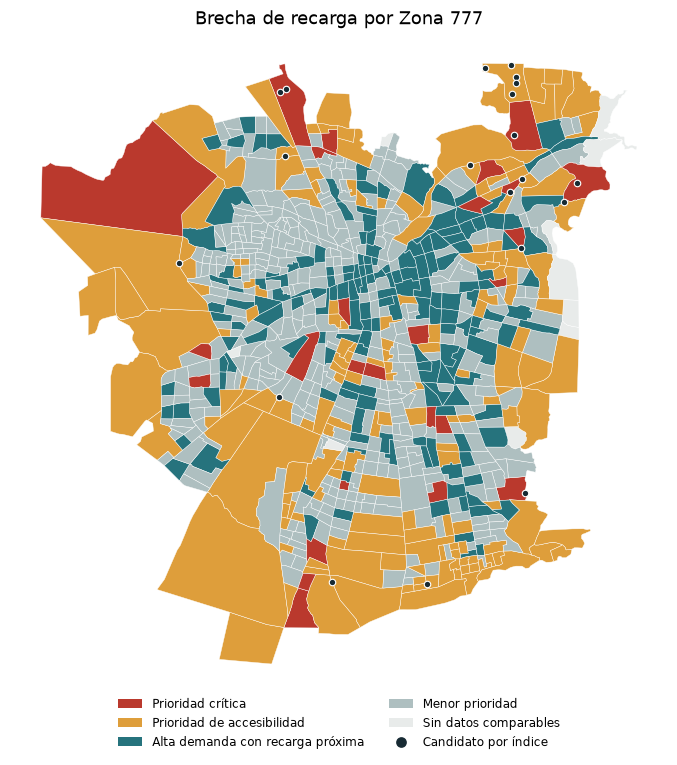

Verificación completada. Mapa: resultados_integral\Live_Demo_BIP.html


In [34]:
fig, ax = plt.subplots(figsize=(8, 7))
parches, tonos = [], []
for z in zonas.itertuples(index=False):
    for poligono in shapely.get_parts(geometrias[z.zona_777]):
        parches.append(Polygon(poligono.exterior.coords))
        tonos.append(COLORES[z.cuadrante])
ax.add_collection(PatchCollection(parches, facecolors=tonos, edgecolors='white', linewidths=.28))
ax.scatter(ranking.X_UTM, ranking.Y_UTM, s=18, facecolor='#172a33', edgecolor='white', linewidth=.75, zorder=3)
ax.autoscale()
ax.set(aspect='equal', title='Brecha de recarga por Zona 777')
ax.axis('off')
leyenda = [Patch(facecolor=color, label=nombre) for nombre,color in COLORES.items()]
leyenda.append(plt.Line2D([], [], color='#172a33', marker='o', linestyle='none', label='Candidato por índice'))
ax.legend(handles=leyenda, loc='lower center', bbox_to_anchor=(.5,-.10), ncol=2, frameon=False, fontsize=8)
guardar_figura(fig, '09_mapa_zona777.png')

ruta_mapa = RESULTADOS / 'Live_Demo_BIP.html'
paradas_bus_mapa = maestro[['CODIGO_PUBLICO','X_UTM','Y_UTM']].rename(
    columns={'CODIGO_PUBLICO':'nombre','X_UTM':'x','Y_UTM':'y'}).assign(modo='Bus')
transporte = pd.concat([paradas_bus_mapa, estaciones], ignore_index=True)
exportar_mapa(ruta_mapa, PLANTILLA_MAPA, geometrias, zonas, df_bip, candidatos, cobertura_comparable, transporte)

assert len(zonas) == len(geometrias) and zonas.zona_777.is_unique
assert zonas.puntos_bip_internos.sum() == df_bip.zona_777.notna().sum()
assert zonas.loc[con_datos, 'cluster'].notna().all()
assert zonas.loc[con_datos, 'pct_subidas_sin_300m'].ge(zonas.loc[con_datos, 'pct_subidas_sin_500m']).all()
assert maestro.PARADA.is_unique and maestro.SUBIDAS_LABORAL.ge(0).all()
assert maestro.bip_en_500m.eq(0).eq(maestro.distancia_min_bip_m.gt(500)).all()
assert maestro.bip_en_300m.eq(0).eq(maestro.distancia_min_bip_m.gt(300)).all()
assert ranking.PARADA.is_unique and ranking.bip_en_500m.eq(0).all()
assert (pdist(ranking[['X_UTM','Y_UTM']]) >= SEPARACION_CANDIDATOS_M).all()
assert cobertura_comparable.groupby('metodo').sitios.max().eq(presupuesto_comun).all()
for _, seleccion in cobertura.groupby('metodo'):
    puntos = candidatos.set_index('PARADA').loc[seleccion.paradero, ['X_UTM','Y_UTM']]
    assert seleccion.paradero.is_unique
    assert (pdist(puntos) >= SEPARACION_CANDIDATOS_M).all()
assert cobertura.groupby('metodo').subidas_acumuladas_con_cobertura.diff().dropna().ge(0).all()
assert len(serie_df) == 168 and auditoria_viajes.viajes_validos.sum() == viajes_diarios.viajes.sum()
assert metricas_temporales.groupby('Modelo').Fecha_test.nunique().eq(3).all()
assert (serie_df.viajes_totales.sum() > 0) and ruta_mapa.stat().st_size > 10000

final_cobertura = cobertura_comparable.groupby('metodo').tail(1).set_index('metodo')
resumen = {
    'viajes_validos_semana': int(serie_df.viajes_totales.sum()), 'viajes_sin_poligono': int(fuera_zona),
    'zonas_en_cartografia': len(zonas), 'zonas_comparables': int(con_datos.sum()),
    'zonas_criticas': int(criticas.sum()), 'zonas_criticas_sin_puntos_internos': int((criticas & sin_carga).sum()),
    'p75_viajes_zona': float(umbral_viajes), 'p75_pct_brecha_zona': float(umbral_brecha),
    'puntos_recarga_intermodal_aeropuerto': int(df_bip.ENTIDAD.eq('INTERMODAL AEROPUERTO').sum()),
    'estaciones_metro_con_recarga': int(df_bip.ENTIDAD.eq('METRO').sum()),
    'filas_metro_originales': len(auditoria_metro),
    'puntos_metro_originales_unicos': len(auditoria_metro.drop_duplicates(['este_xlsx','norte_xlsx'])),
    'filas_metro_desfase_gt_500m': int(auditoria_metro.desfase_m.gt(500).sum()),
    'puntos_bip': len(df_bip), 'puntos_sin_poligono': int(df_bip.zona_777.isna().sum()),
    'asignaciones_bip_con_solape': solapes_bip, 'asignaciones_paradas_con_solape': solapes_paradas,
    'asignaciones_gtfs_con_solape': solapes_gtfs, 'paraderos_gtfs_sin_poligono': int(maestro.zona_777.isna().sum()),
    'concordancia_zona_diccionario_cartografia': float(concordancia),
    'paraderos_bus_enlazados': len(maestro), 'paraderos_bus_dtpm': len(demanda_bus),
    'pct_subidas_dtpm_con_ubicacion': float(100*fraccion_subidas),
    'pct_subidas_por_codigo_interno_diccionario': float(100*fraccion_historica),
    'paraderos_criticos': int(maestro.prioridad_territorial.eq('Prioridad crítica').sum()),
    'paraderos_aislados_500m': int(maestro.bip_en_500m.eq(0).sum()),
    'k': k_optimo, 'silueta': float(tabla_k.silueta.max()),
    'pca_varianza_2d': float(pca.explained_variance_ratio_.sum()), 'perfil_mayor_brecha': perfil_mayor_brecha,
    'perfiles_alta_demanda_y_brecha': perfiles.index[perfiles.alta_demanda_y_brecha].to_list(),
    'n_candidatos': len(ranking), 'n_elegibles': len(candidatos),
    'presupuesto_comparable': presupuesto_comun,
    'cobertura_500m_final': final_cobertura.subidas_acumuladas_con_cobertura.to_dict(),
    'metricas_espaciales': metricas_espaciales.to_dict(orient='records'),
    'metricas_temporales': promedios_t.reset_index().to_dict(orient='records'),
    'psm_descriptivo': reporte_psm,
    'fuentes': [p.relative_to(RAIZ).as_posix() for p in [ruta_bip, ruta_dic, ruta_dtpm, ruta_shape, ruta_gtfs]],
    'mapa': ruta_mapa.relative_to(RAIZ).as_posix(),
}
(RESULTADOS / 'resumen_auditoria.json').write_text(json.dumps(resumen, ensure_ascii=False, indent=2), encoding='utf-8')
enlace = escape(ruta_mapa.relative_to(RAIZ).as_posix(), quote=True)
display(HTML(f'<a href="{enlace}" target="_blank" rel="noopener">Abrir mapa interactivo</a>'))
print('Verificación completada. Mapa:', ruta_mapa.relative_to(RAIZ))

## 10. Resultados y límites

El resumen se calcula sobre las salidas de esta ejecución. Los radios representan distancias en línea recta. La accesibilidad a pie debe verificarse con calles, cruces, barreras y horarios. Vivienda, densidad comercial y modos alternativos de pago pueden cambiar la interpretación de la brecha. El catastro es anterior a la demanda y no mide recargas, capacidad ni disponibilidad efectiva. Los viajes registrados y las subidas son unidades diferentes y pueden incluir más de un registro por persona. La simulación mantiene fija la demanda y supone disponibilidad de los sitios seleccionados.

In [35]:
esp = metricas_espaciales.iloc[0]
temp_nombre, temp = next(iter(promedios_t.iterrows()))
ridge_mae = metricas_espaciales.set_index('Modelo').MAE
top = ranking.iloc[0]
perfil_brecha = perfiles.loc[perfil_mayor_brecha]
texto_perfiles = (f'{perfiles.alta_demanda_y_brecha.sum()} perfiles cruzan ambos P75 en sus medianas.'
                  if perfiles.alta_demanda_y_brecha.any() else 'Ningún perfil cruza ambos P75 en sus medianas.')
display(Markdown(f"""
- **Diagnóstico.** {int(criticas.sum())} de {int(con_datos.sum())} zonas comparables tienen alta demanda y alta brecha. En {int((criticas & sin_carga).sum())} de ellas el catastro no ubica puntos dentro del polígono. El cruce por distancia también captura el acceso desde zonas vecinas.
- **Perfiles.** K-Means eligió **k={k_optimo}** (silueta {numero(tabla_k.silueta.max(), 2)}). El perfil {perfil_mayor_brecha} agrupa {int(perfil_brecha.zonas)} zonas y tiene una brecha mediana de {numero(perfil_brecha.pct_subidas_sin_500m, 1)}%. {texto_perfiles} PCA conserva {numero(100*pca.explained_variance_ratio_.sum(), 1)}% de la varianza.
- **Regresión.** {esp.Modelo} logra el menor MAE entre los modelos de la entrega final en esta partición ({numero(esp.MAE, 1)} subidas/día). Ridge con recarga registra {numero(ridge_mae['Ridge con recarga'], 1)}, frente a {numero(ridge_mae['Ridge sin recarga'], 1)} de Ridge sin recarga. La diferencia caracteriza este conjunto de prueba.
- **Sensibilidad de la regresión.** Random Forest con objetivo logarítmico registró un MAE de {numero(metricas_log['MAE'], 1)} subidas/día y un RMSE de {numero(metricas_log['RMSE'], 1)} en las mismas comunas de prueba. Las dos métricas penalizan los errores grandes de forma distinta.
- **Pronóstico.** {temp_nombre} obtiene el menor MAE medio ({numero(temp.MAE)} viajes/hora) en tres ventanas. El MAE del baseline estacional es {numero(promedios_t.loc['Ingenuo estacional (24 h)', 'MAE'])} viajes/hora.
- **Ubicación.** El primer sitio por índice es **{top.CODIGO_PUBLICO}**, {top.COMUNA.title()}, con {numero(top.SUBIDAS_LABORAL)} subidas/día y {numero(top.distancia_min_bip_m)} m al bip! más cercano. Con {presupuesto_comun} sitios por estrategia bajo el escenario de 500 m, la cobertura marginal alcanza {numero(final_cobertura.loc['Cobertura marginal', 'subidas_acumuladas_con_cobertura'])} subidas/día ya registradas. El ranking por índice alcanza {numero(final_cobertura.loc['Índice del avance', 'subidas_acumuladas_con_cobertura'])}.
"""))


- **Diagnóstico.** 26 de 793 zonas comparables tienen alta demanda y alta brecha. En 3 de ellas el catastro no ubica puntos dentro del polígono. El cruce por distancia también captura el acceso desde zonas vecinas.
- **Perfiles.** K-Means eligió **k=2** (silueta 0,47). El perfil 1 agrupa 110 zonas y tiene una brecha mediana de 70,7%. Ningún perfil cruza ambos P75 en sus medianas. PCA conserva 75,4% de la varianza.
- **Regresión.** Ridge con recarga logra el menor MAE entre los modelos de la entrega final en esta partición (175,8 subidas/día). Ridge con recarga registra 175,8, frente a 179,8 de Ridge sin recarga. La diferencia caracteriza este conjunto de prueba.
- **Sensibilidad de la regresión.** Random Forest con objetivo logarítmico registró un MAE de 141,0 subidas/día y un RMSE de 417,8 en las mismas comunas de prueba. Las dos métricas penalizan los errores grandes de forma distinta.
- **Pronóstico.** Ingenuo estacional (24 h) obtiene el menor MAE medio (5.847 viajes/hora) en tres ventanas. El MAE del baseline estacional es 5.847 viajes/hora.
- **Ubicación.** El primer sitio por índice es **PC907**, Lo Barnechea, con 695 subidas/día y 2.041 m al bip! más cercano. Con 20 sitios por estrategia bajo el escenario de 500 m, la cobertura marginal alcanza 42.784 subidas/día ya registradas. El ranking por índice alcanza 23.748.


---

Los gráficos se calculan con las fuentes de esta ejecución. Los conteos del comienzo de CSV de distinto tamaño se sustituyeron por perfiles de días completos. Las métricas y las conclusiones se vuelven a calcular. El diagnóstico comunal queda como EDA, el ajuste de propensión como comparación descriptiva y la simulación como cobertura potencial de las subidas registradas.